# Task 2: Bike Trip and Station Profiles


### Data setup

<span style="color: red"><strong>IMPORTANT! READ THIS:</strong></span>

**This notebook read `trips_valid.csv` which is an output file of the Task 1 notebook. Make sure you've run Task 1 notebook before running this one.**


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

cities = pd.read_csv("../data/cities.csv")
bikes = pd.read_csv("../data/bikes.csv")
bike_types = pd.read_csv("../data/bike_types.csv")
trips_valid = pd.read_csv("../data/trips_valid.csv")


## Part A: Clustering Bike Trips

### Preprocessing 1: Split trips by propulsion type. 

<span style="color: red"><strong>READ THIS TO SAVE READING TIME:</strong></span>

Clustering result under this preprocessing method is not interesting for the following three reasons. 

For time saving purpose, please jump to "Preprocessing 2".
- There's not much difference between trips made by classic bikes and electric bikes.
- Using trip duration feature, two clusters appears: short trip and long trip.
- Using trip start hour feature, two clusters appears, with no significant meaning.



In [5]:
# TODO: Divide bike trips into two groups: trips made by classic bikes, and those made by electric bikes

trips_valid = trips_valid.merge(
    cities[["id", "timezone"]].rename(columns={"id": "city_id"}),
    on="city_id",
    how="left",
)

classic_trips = trips_valid[trips_valid["propulsion_type"].eq("human")].copy()
electric_trips = trips_valid[trips_valid["propulsion_type"].eq("electric_assist")].copy()

print(f"Classic trips: {classic_trips.shape[0]}")
print(f"Electric trips: {electric_trips.shape[0]}")


Classic trips: 978939
Electric trips: 180091


#### Clustering using trip duration feature

Classic group best K: 2
{'k': [2, 3, 4, 5, 6], 'silhouette': [0.5856, 0.5529, 0.5405, 0.5437, 0.539], 'inertia': [3692.7026, 1836.5998, 1112.2914, 748.3533, 542.795]}
Electric group best K: 2
{'k': [2, 3, 4, 5, 6], 'silhouette': [0.5795, 0.5695, 0.5383, 0.541, 0.546], 'inertia': [4178.1397, 1839.371, 1146.1002, 784.199, 536.9395]}


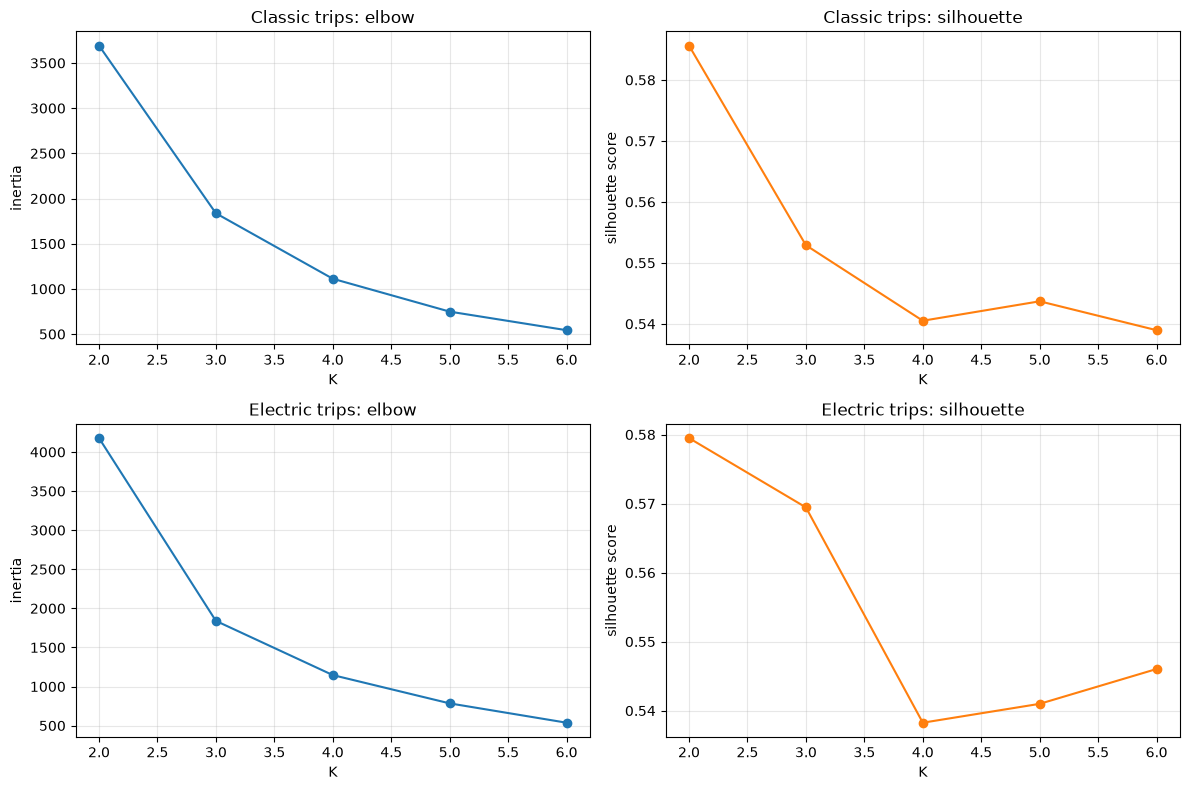

In [6]:
# TODO: sample 10000 trips in each group

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

rng = np.random.RandomState(42)
sample_size = 10_000

classic_sample = classic_trips.sample(
    n=min(sample_size, len(classic_trips)),
    random_state=rng.randint(0, 10_000),
).copy()
electric_sample = electric_trips.sample(
    n=min(sample_size, len(electric_trips)),
    random_state=rng.randint(0, 10_000),
).copy()

# TODO: Perform KMeans for K = 2 to 6.
#       Use only the trip duration feature and silhouette analysis to select the best K
#       And visualize the selection process
# TODO: We log-transform duration because trip lengths are right-skewed and KMeans works better on a more balanced scale.
# TODO: Compare silhouette scores across K = 2..6 and choose the K with the highest score.
# TODO: Inspect the resulting cluster distributions to confirm the selected K is meaningful.

def prepare_duration_feature(df):
    duration_minutes = df["duration"] / 60.0
    duration_minutes = duration_minutes.clip(lower=1e-9)
    return np.log(duration_minutes.to_numpy()).reshape(-1, 1)


def evaluate_kmeans(df):
    # TODO: Standardize the transformed duration feature before clustering.
    X = StandardScaler().fit_transform(prepare_duration_feature(df))
    ks = list(range(2, 7))
    sil_scores = []
    inertias = []
    models = {}

    for k in ks:
        model = KMeans(n_clusters=k, n_init=10, random_state=42)
        labels = model.fit_predict(X)
        sil_scores.append(silhouette_score(X, labels))
        inertias.append(model.inertia_)
        models[k] = model

    best_k = ks[int(np.argmax(sil_scores))]
    return ks, sil_scores, inertias, X, best_k, models


cluster_results = {}
for group_name, group_df in [("classic", classic_sample), ("electric", electric_sample)]:
    # TODO: Save the silhouette and elbow results for each group.
    ks, sil_scores, inertias, X, best_k, models = evaluate_kmeans(group_df)
    cluster_results[group_name] = {
        "ks": ks,
        "sil_scores": sil_scores,
        "inertias": inertias,
        "best_k": best_k,
        "X": X,
        "model": models[best_k],
    }
    print(f"{group_name.title()} group best K: {best_k}")
    print({"k": list(ks), "silhouette": [round(v, 4) for v in sil_scores], "inertia": [round(v, 4) for v in inertias]})

# TODO: Plot both the elbow curve and silhouette score curve for both groups.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, (group_name, result) in enumerate(cluster_results.items()):
    axes[row, 0].plot(result["ks"], result["inertias"], marker="o", color="tab:blue")
    axes[row, 0].set_title(f"{group_name.title()} trips: elbow")
    axes[row, 0].set_xlabel("K")
    axes[row, 0].set_ylabel("inertia")
    axes[row, 0].grid(alpha=0.3)

    axes[row, 1].plot(result["ks"], result["sil_scores"], marker="o", color="tab:orange")
    axes[row, 1].set_title(f"{group_name.title()} trips: silhouette")
    axes[row, 1].set_xlabel("K")
    axes[row, 1].set_ylabel("silhouette score")
    axes[row, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


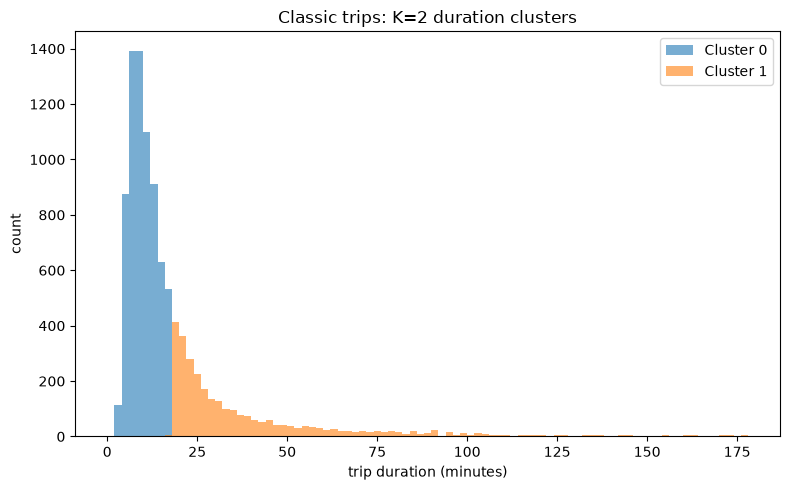

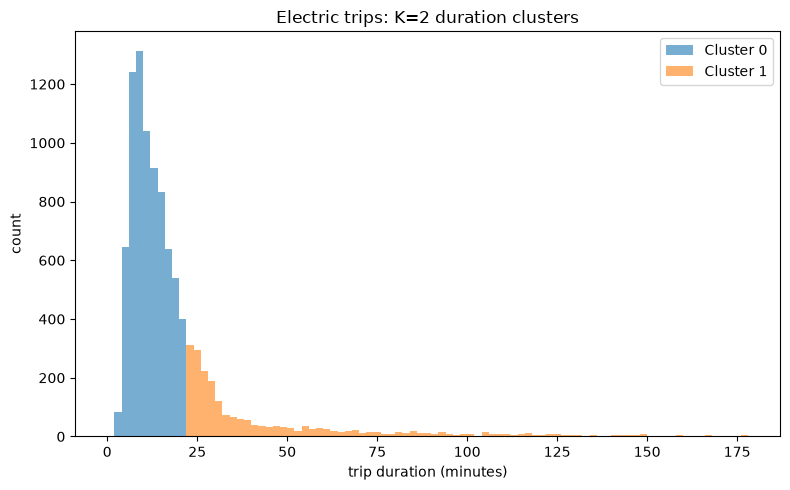

In [7]:
# TODO: Visualize the clusters with the best K.
# TODO: Use the best K from the silhouette analysis and plot the duration distribution by cluster.
# TODO: Check whether the clusters correspond to short vs long trip patterns.
for group_name, group_df in [("classic", classic_sample), ("electric", electric_sample)]:
    df = group_df.copy()
    df["duration_min"] = df["duration"] / 60.0
    X = StandardScaler().fit_transform(prepare_duration_feature(df))
    model = KMeans(
        n_clusters=cluster_results[group_name]["best_k"],
        n_init=10,
        random_state=42,
    )
    labels = model.fit_predict(X)
    df["cluster"] = labels

    fig, ax = plt.subplots(figsize=(8, 5))
    for cluster_id in range(cluster_results[group_name]["best_k"]):
        ax.hist(
            df.loc[df["cluster"] == cluster_id, "duration_min"],
            bins=np.arange(0, 180, 2),
            alpha=0.6,
            label=f"Cluster {cluster_id}",
        )

    ax.set_title(f"{group_name.title()} trips: K={cluster_results[group_name]['best_k']} duration clusters")
    ax.set_xlabel("trip duration (minutes)")
    ax.set_ylabel("count")
    ax.legend()
    plt.tight_layout()
    plt.show()


#### Clustering using trip start time feature

Becareful all times in trips_valid are UTC, convert to local time first.

Classic group best K: 2
{'k': [2, 3, 4, 5, 6], 'silhouette': [0.5965, 0.5429, 0.5251, 0.5541, 0.551], 'inertia': [3159.3199, 1651.1399, 1055.8353, 610.007, 409.7789]}
Electric group best K: 2
{'k': [2, 3, 4, 5, 6], 'silhouette': [0.5881, 0.5709, 0.537, 0.5443, 0.5481], 'inertia': [3134.1351, 1489.8316, 965.0474, 638.104, 421.3841]}


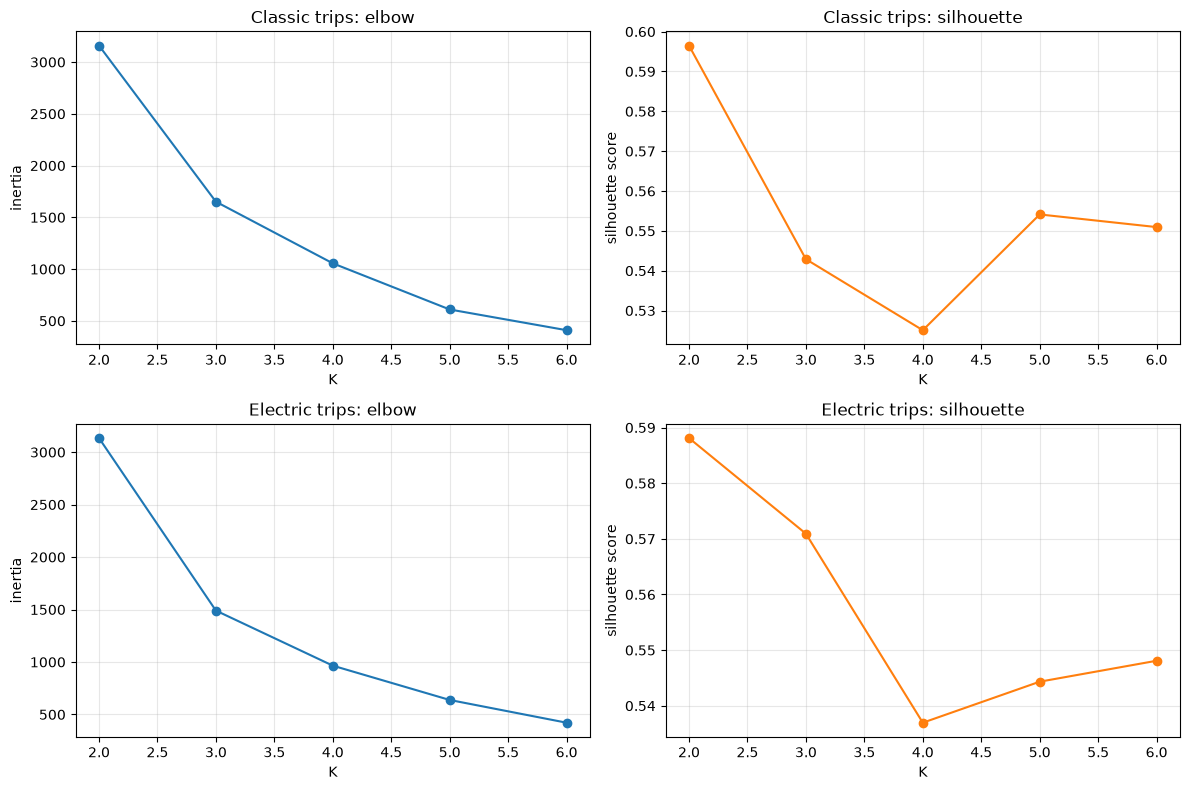

In [8]:
# TODO: Convert trip start times from UTC to local time using the city timezone.
# TODO: Create a start_hour feature for clustering (hour of the day, local time).
# TODO: sample 10000 trips in each group


def prepare_start_time_feature(df):
    df = df.copy()
    df["start_dt"] = pd.to_datetime(df["time_start"], unit="s", utc=True)
    df["start_hour"] = 0.0
    for timezone, row_indices in df.groupby("timezone").groups.items():
        local_time = df.loc[row_indices, "start_dt"].dt.tz_convert(timezone)
        df.loc[row_indices, "start_hour"] = (
            local_time.dt.hour + local_time.dt.minute / 60.0
        ).to_numpy()
    return df[["start_hour"]]


# TODO: Run KMeans for K = 2 to 6 using the start_hour feature only.
# TODO: Compute silhouette scores for each K.
# TODO: Select the best K based on the highest silhouette score.
# TODO: Plot silhouette score vs. K for classic and electric groups.


classic_sample = classic_trips.sample(
    n=min(10_000, len(classic_trips)),
    random_state=42,
).copy()
electric_sample = electric_trips.sample(
    n=min(10_000, len(electric_trips)),
    random_state=42,
).copy()

cluster_results = {}
for group_name, group_df in [("classic", classic_sample), ("electric", electric_sample)]:
    features = prepare_start_time_feature(group_df)
    X = StandardScaler().fit_transform(features)
    ks = list(range(2, 7))
    sil_scores = []
    inertias = []
    models = {}

    for k in ks:
        model = KMeans(n_clusters=k, n_init=10, random_state=42)
        labels = model.fit_predict(X)
        sil_scores.append(silhouette_score(X, labels))
        inertias.append(model.inertia_)
        models[k] = model

    best_k = ks[int(np.argmax(sil_scores))]
    cluster_results[group_name] = {
        "ks": ks,
        "sil_scores": sil_scores,
        "inertias": inertias,
        "best_k": best_k,
        "models": models,
    }
    print(f"{group_name.title()} group best K: {best_k}")
    print({"k": list(ks), "silhouette": [round(v, 4) for v in sil_scores], "inertia": [round(v, 4) for v in inertias]})

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, (group_name, result) in enumerate(cluster_results.items()):
    axes[row, 0].plot(result["ks"], result["inertias"], marker="o", color="tab:blue")
    axes[row, 0].set_title(f"{group_name.title()} trips: elbow")
    axes[row, 0].set_xlabel("K")
    axes[row, 0].set_ylabel("inertia")
    axes[row, 0].grid(alpha=0.3)

    axes[row, 1].plot(result["ks"], result["sil_scores"], marker="o", color="tab:orange")
    axes[row, 1].set_title(f"{group_name.title()} trips: silhouette")
    axes[row, 1].set_xlabel("K")
    axes[row, 1].set_ylabel("silhouette score")
    axes[row, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


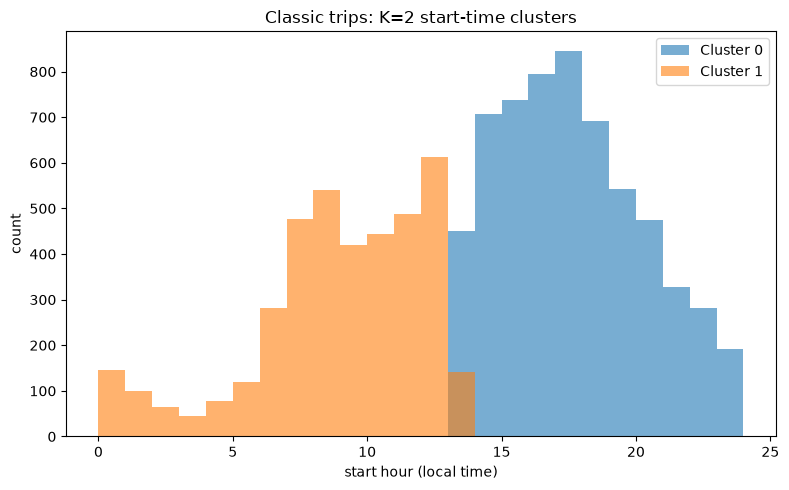

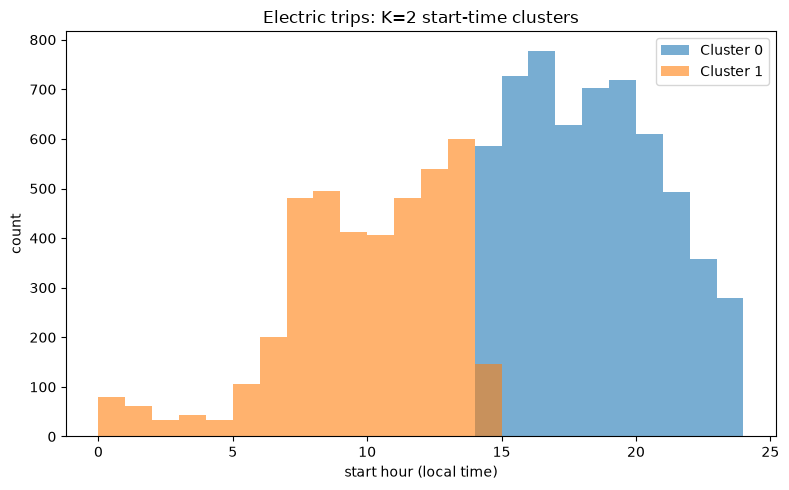

In [9]:

# TODO: Visualize the clusters with the best K using start_hour on the x-axis.
# TODO: Optionally compare the resulting cluster centers by hour-of-day.
for group_name, group_df in [("classic", classic_sample), ("electric", electric_sample)]:
    df = group_df.copy()
    df = df.join(prepare_start_time_feature(df))
    model = cluster_results[group_name]["models"][cluster_results[group_name]["best_k"]]
    X = StandardScaler().fit_transform(df[["start_hour"]])
    df["cluster"] = model.fit_predict(X)

    fig, ax = plt.subplots(figsize=(8, 5))
    for cluster_id in range(cluster_results[group_name]["best_k"]):
        ax.hist(
            df.loc[df["cluster"] == cluster_id, "start_hour"],
            bins=np.arange(0, 25, 1),
            alpha=0.6,
            label=f"Cluster {cluster_id}",
        )

    ax.set_title(f"{group_name.title()} trips: K={cluster_results[group_name]['best_k']} start-time clusters")
    ax.set_xlabel("start hour (local time)")
    ax.set_ylabel("count")
    ax.legend()
    plt.tight_layout()
    plt.show()


### Preprocessing 2: Split trips by weekday/weekend

#### Clustering using trip start time feature

We run KMeans for clustering. We split trips into weekend and weekdays. We remove duration outliers so kmeans works perfectly.

In [10]:
# TODO: Reuse Task 1's cleaned trips_valid table; do not reload the raw trips CSV.
# TODO: Convert UTC start times to each city's local time before splitting by weekday/weekend.
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

weekday_weekend_trips = trips_valid.copy()
weekday_weekend_trips["start_dt"] = pd.to_datetime(
    weekday_weekend_trips["time_start"], unit="s", utc=True
)
weekday_weekend_trips["start_hour"] = np.nan
weekday_weekend_trips["is_weekend"] = False

for timezone, row_indices in weekday_weekend_trips.groupby("timezone").groups.items():
    local_start = weekday_weekend_trips.loc[row_indices, "start_dt"].dt.tz_convert(timezone)
    weekday_weekend_trips.loc[row_indices, "start_hour"] = (
        local_start.dt.hour + local_start.dt.minute / 60.0
    ).to_numpy()
    weekday_weekend_trips.loc[row_indices, "is_weekend"] = (
        local_start.dt.day_of_week >= 5
    ).to_numpy()

# TODO: Remove the longest 1% of durations
duration_cap = weekday_weekend_trips["duration"].quantile(0.99)
weekday_weekend_trips = weekday_weekend_trips.loc[
    weekday_weekend_trips["duration"] <= duration_cap
].copy()

weekday_trips = weekday_weekend_trips.loc[
    ~weekday_weekend_trips["is_weekend"]
].copy()
weekend_trips = weekday_weekend_trips.loc[
    weekday_weekend_trips["is_weekend"]
].copy()
weekday_weekend_samples = {
    "Weekday": weekday_trips.sample(
        n=min(10_000, len(weekday_trips)), random_state=42
    ),
    "Weekend": weekend_trips.sample(
        n=min(10_000, len(weekend_trips)), random_state=42
    ),
}

print(f"99th-percentile duration cap: {duration_cap / 60:.1f} minutes")
print(f"Weekday trips: {len(weekday_trips):,}")
print(f"Weekend trips: {len(weekend_trips):,}")
for name, group in [("Weekday", weekday_trips), ("Weekend", weekend_trips)]:
    print(f"\n{name} duration (minutes):")
    print((group["duration"] / 60).describe().round(2))


99th-percentile duration cap: 170.0 minutes
Weekday trips: 886,268
Weekend trips: 263,506

Weekday duration (minutes):
count    886268.00
mean         17.59
std          20.11
min           2.02
25%           7.00
50%          11.00
75%          19.00
max         170.00
Name: duration, dtype: float64

Weekend duration (minutes):
count    263506.00
mean         21.56
std          23.22
min           2.02
25%           9.00
50%          14.00
75%          24.00
max         170.00
Name: duration, dtype: float64


In [11]:
# TODO: Standardize each feature and evaluate inertia and silhouette for K=2..8.
def evaluate_weekday_weekend_clustering(feature_data):
    results = {}
    ks = list(range(2, 9))
    for name, features in feature_data.items():
        scaler = StandardScaler()
        X = scaler.fit_transform(features)
        inertias, silhouette_scores = [], []
        for k in ks:
            model = KMeans(n_clusters=k, n_init=10, random_state=42)
            labels = model.fit_predict(X)
            inertias.append(model.inertia_)
            silhouette_scores.append(
                silhouette_score(
                    X, labels, sample_size=min(2_000, len(X)), random_state=42
                )
            )
        results[name] = {
            "X": X,
            "scaler": scaler,
            "ks": ks,
            "inertias": inertias,
            "silhouette_scores": silhouette_scores,
        }
        print(
            f"{name}: silhouette scores "
            f"{[round(score, 3) for score in silhouette_scores]}"
        )
    return results


# TODO: Prepare one figure of inertia and silhouette metrics for each clustering feature.
def plot_clustering_metrics(results, feature_name):
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    for row, (name, result) in enumerate(results.items()):
        axes[row, 0].plot(result["ks"], result["inertias"], marker="o")
        axes[row, 0].set_title(f"{name}: {feature_name} elbow")
        axes[row, 0].set_xlabel("k")
        axes[row, 0].set_ylabel("inertia")
        axes[row, 1].plot(
            result["ks"], result["silhouette_scores"], marker="o", color="tab:orange"
        )
        axes[row, 1].set_title(f"{name}: {feature_name} silhouette")
        axes[row, 1].set_xlabel("k")
        axes[row, 1].set_ylabel("silhouette score")
    plt.tight_layout()
    plt.show()


comparison_k = 3
cluster_colors = ["tab:blue", "tab:orange", "tab:green"]


In [12]:
# TODO: Evaluate K-means using local start hour for each weekday/weekend sample.
start_hour_features = {
    name: sample[["start_hour"]].to_numpy()
    for name, sample in weekday_weekend_samples.items()
}
start_hour_results = evaluate_weekday_weekend_clustering(start_hour_features)


Weekday: silhouette scores [0.601, 0.555, 0.551, 0.557, 0.552, 0.55, 0.543]
Weekend: silhouette scores [0.576, 0.577, 0.549, 0.557, 0.542, 0.548, 0.538]


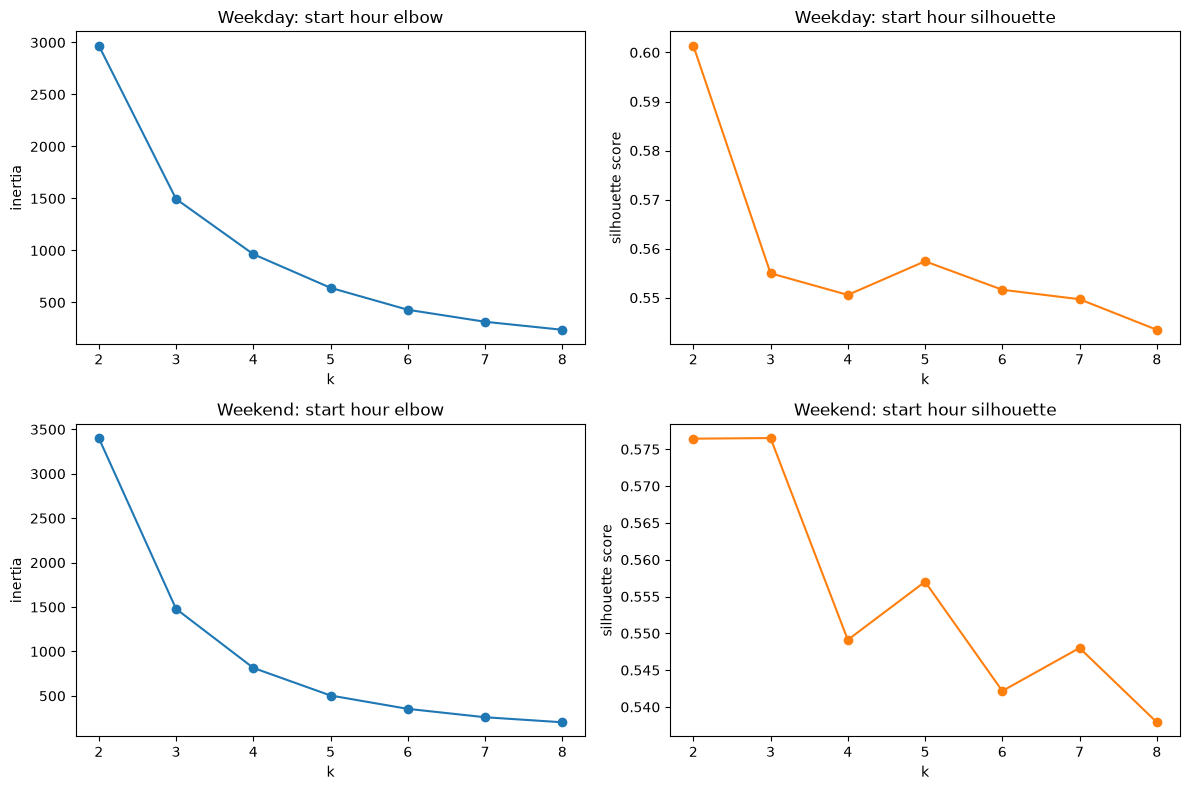

In [13]:
# TODO: Plot the start-hour elbow and silhouette diagnostics.
plot_clustering_metrics(start_hour_results, "start hour")


Weekdays:
Elbow(inertia): after k=3 the curve bend slowly so that means elbow is at 3
Silhouette: the peak is at k=2(0.56) and drops to 0.54 at k=3.
The two methods points different but we choose k=3 as through this we can compare weekdays and weekedns and it divide the time into 3 parts morning, afternoon and evening which is very reasonable.

Weekends:
Elbow:The big drop is from k=2 to 3 and afer 3 it drops slowly
Silhouette : It is highest at k=2 and after that it stays low
So both methods points slightly different like elbow says 3 and silhouette says 2
let take k=3 (supporting by elbow) in this way we can compare weekday and weekly pattern as well

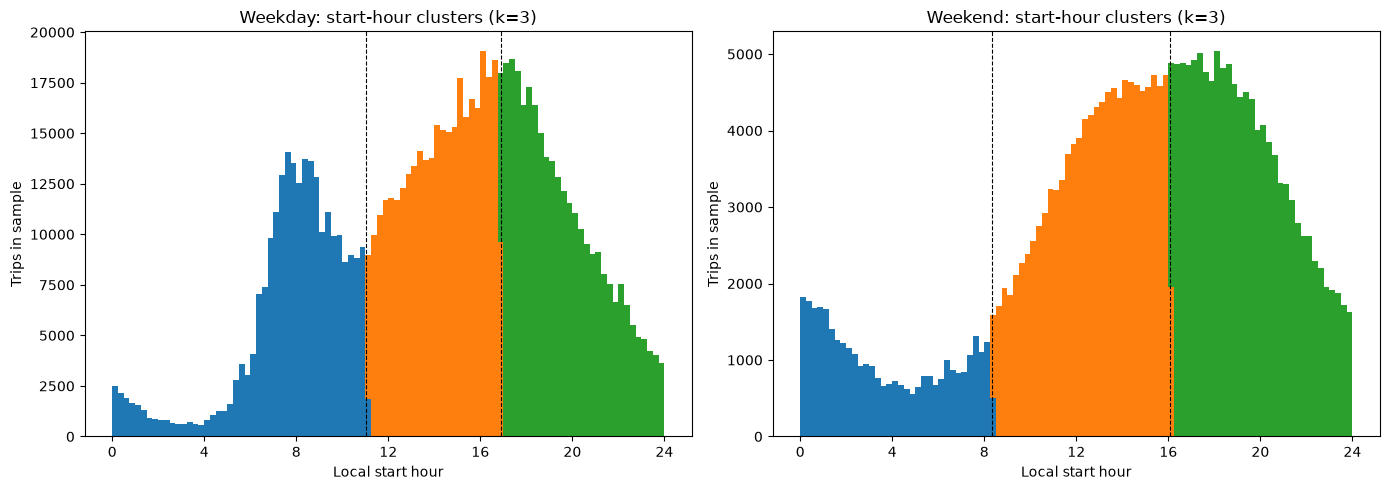

In [14]:
# TODO: Predict clusters for each full group so plotted trip counts match the source discoveries.
# TODO: Visualize each group's three local start-hour clusters in one figure.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, result) in zip(axes, start_hour_results.items()):
    model = KMeans(n_clusters=comparison_k, n_init=10, random_state=42).fit(result["X"])
    centers = result["scaler"].inverse_transform(model.cluster_centers_).ravel()
    cluster_order = np.argsort(np.argsort(centers))
    group = weekday_trips if name == "Weekday" else weekend_trips
    full_X = result["scaler"].transform(group[["start_hour"]].to_numpy())
    ordered_labels = cluster_order[model.predict(full_X)]
    hours = group["start_hour"].to_numpy()
    ax.hist(
        [hours[ordered_labels == cluster] for cluster in range(comparison_k)],
        bins=np.arange(0, 24.25, 0.25),
        stacked=True,
        color=cluster_colors,
    )
    boundaries = np.sort(centers)
    for boundary in (boundaries[:-1] + boundaries[1:]) / 2:
        ax.axvline(boundary, color="black", linestyle="--", linewidth=0.8)
    ax.set_title(f"{name}: start-hour clusters (k={comparison_k})")
    ax.set_xlabel("Local start hour")
    ax.set_ylabel("Trips in sample")
    ax.set_xticks(range(0, 25, 4))
plt.tight_layout()
plt.show()


Weekday:
Cluster blue: from midnight to almost 11:00. Very few trips from 2:00 to 5:00 and peak trips are from 6am to 8am almost showing that people use it for going to offices, universities and colleges mostly.

Cluster Orange: from 11:00 to 17:00 (mid day) The number of the trips keep rising in this that comprehend people use it for returning back home from schools and universities  or going out for lunch .

Cluster Green: from 17:00 to  midnight: It starts with a peak and then declines showing people use it for returning back from offices and not much for going to the dinner or at night.

Conclusion: In weekdays people use it more in buisness hours more for offices, universities ,school and lunch

Weekends:
Cluster Blue: midnight to 8:00. It is highest at around midnight and falls to lowest at around 5:00. These people are the one who are going home after friday shift of their work. At morning lowest as it's weekend and off day(no office) so less travelling.

Cluster orange: From 8:00 to 16:00 trips increases steadily till mid day. More use at mid day indicating for lunch or activities.

Cluster Green: from 16:00 to mid night.Highest is around 16:00-17:00 and slowly decreases.

Conclusion: No morining peak . Highest peaks at mid day or late afternoon showing leisure use instead of commuting

Weekday is split into morning , afternoon and evening. 
weekend is split into night, day and evening. On weekends tere is about 4 times less trips per 15 min than on weekdays


#### Clustering using trip duration feature

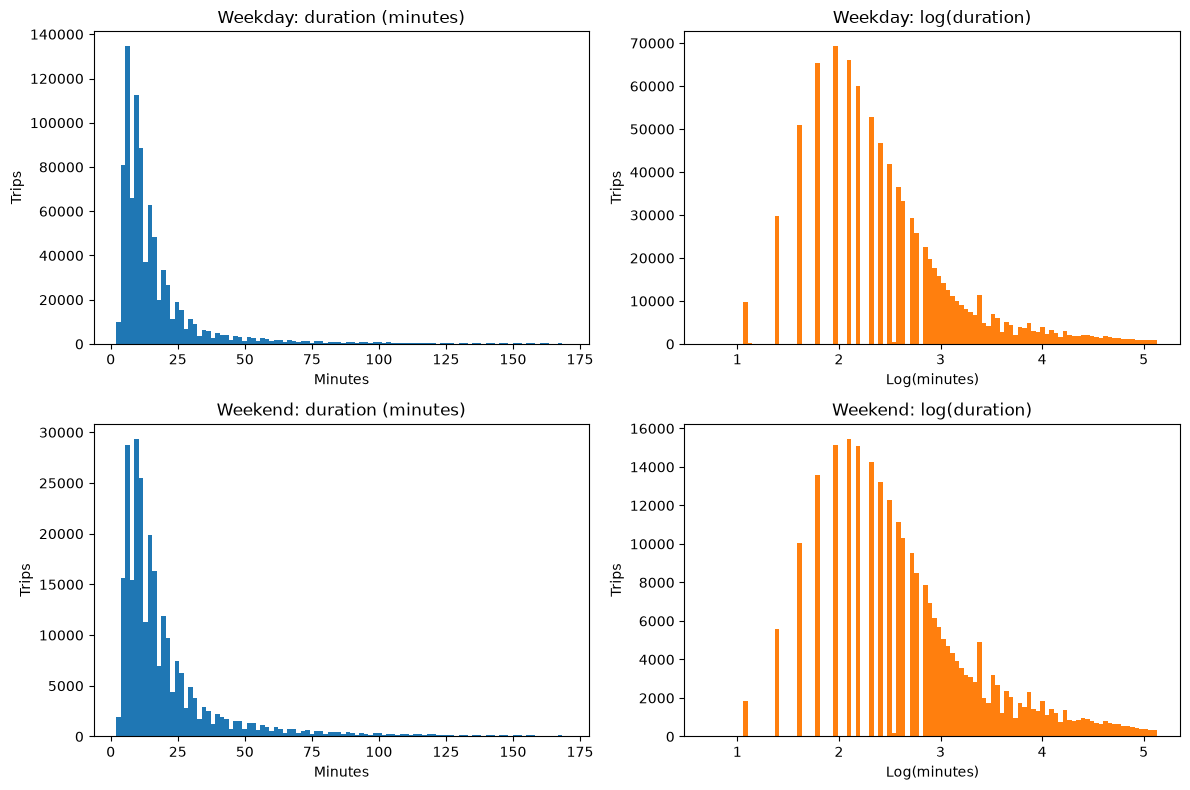

In [15]:
# TODO: Plot raw and log-transformed duration distributions for weekdays and weekends.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, (name, group) in enumerate(
    [("Weekday", weekday_trips), ("Weekend", weekend_trips)]
):
    minutes = group["duration"] / 60
    axes[row, 0].hist(minutes, bins=100, color="tab:blue")
    axes[row, 0].set_title(f"{name}: duration (minutes)")
    axes[row, 0].set_xlabel("Minutes")
    axes[row, 0].set_ylabel("Trips")
    axes[row, 1].hist(np.log(minutes), bins=100, color="tab:orange")
    axes[row, 1].set_title(f"{name}: log(duration)")
    axes[row, 1].set_xlabel("Log(minutes)")
    axes[row, 1].set_ylabel("Trips")
plt.tight_layout()
plt.show()


Duration is right skewed as it can be seen. most trips are upto 5-15mins. Weekends trips are a bit longer .By taking log , it reduces the skew and spread the short trips.

The log spreads out the small duration trips region and it pulls in the tail this will help in kmeans getting more usefull cut points

In [16]:
# TODO: Evaluate K-means using log-transformed duration for each weekday/weekend sample.
duration_feature_data = {
    name: np.log(sample["duration"].to_numpy() / 60).reshape(-1, 1)
    for name, sample in weekday_weekend_samples.items()
}
duration_results = evaluate_weekday_weekend_clustering(duration_feature_data)


Weekday: silhouette scores [0.573, 0.56, 0.55, 0.55, 0.539, 0.556, 0.558]
Weekend: silhouette scores [0.577, 0.56, 0.54, 0.542, 0.545, 0.557, 0.558]


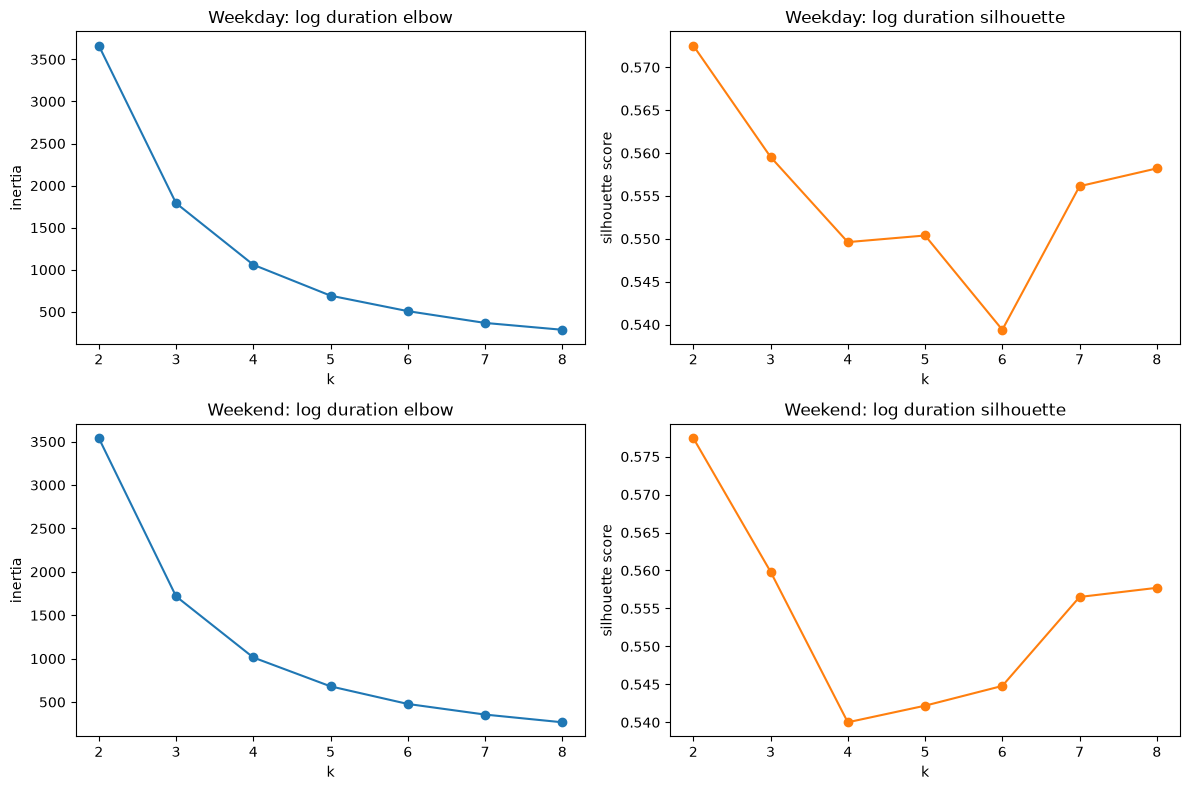

In [17]:
# TODO: Plot the log-duration elbow and silhouette diagnostics.
plot_clustering_metrics(duration_results, "log duration")


Elbow method shows that the curve bends at k=3 in both weekends and weekdays. The silhouette score range is between 0.54 to 0.58 in bith weekend and weekdays showing barely vary with k. Hence we choose k=3.

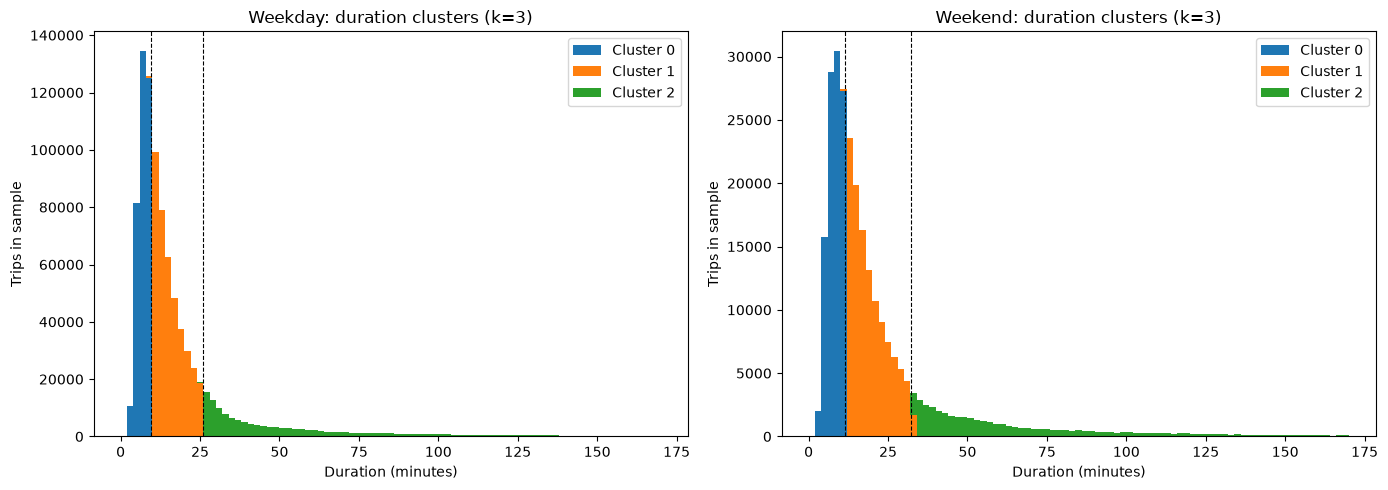

In [18]:
# TODO: Predict clusters for each full group so plotted trip counts match the source discoveries.
# TODO: Visualize three duration clusters, ordered from shortest to longest.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, result) in zip(axes, duration_results.items()):
    model = KMeans(n_clusters=comparison_k, n_init=10, random_state=42).fit(result["X"])
    centers = np.exp(
        result["scaler"].inverse_transform(model.cluster_centers_).ravel()
    )
    cluster_order = np.argsort(np.argsort(centers))
    group = weekday_trips if name == "Weekday" else weekend_trips
    full_log_duration = np.log(group["duration"].to_numpy() / 60).reshape(-1, 1)
    full_X = result["scaler"].transform(full_log_duration)
    ordered_labels = cluster_order[model.predict(full_X)]
    minutes = group["duration"].to_numpy() / 60
    ax.hist(
        [minutes[ordered_labels == cluster] for cluster in range(comparison_k)],
        bins=np.arange(0, duration_cap / 60 + 2, 2),
        stacked=True,
        color=cluster_colors,
        label=[f"Cluster {i}" for i in range(comparison_k)],
    )
    sorted_centers = np.sort(centers)
    for boundary in np.sqrt(sorted_centers[:-1] * sorted_centers[1:]):
        ax.axvline(boundary, color="black", linestyle="--", linewidth=0.8)
    ax.set_title(f"{name}: duration clusters (k={comparison_k})")
    ax.set_xlabel("Duration (minutes)")
    ax.set_ylabel("Trips in sample")
    ax.legend()
plt.tight_layout()
plt.show()


Weekday: (k=3: short,medium,long)

Cluster blue: Short trips about 2 to 10 mins. It is a tall narrow group. Highest bar is of 135,000 trips around 8-10mins. Indicates short trips to station or shops

cluster orange: About 10-28mins (Medium duration trips).Start high and decreases steadily.Normal city rides covering few km.

Cluster Green: Long trips(aeound 28mins or more). A long steady flat tail with few trips. These are leisure or activity rides or bikes kept or long time.


Weekends: (k=3: short,medium,long)
Short trips goes to about 12mins instead of 10mins ,similarly long trips start at about 32 mins instead of abput 28. orange(medium) cluster is wider and drops slowly than weekdays

Conclusion:
Duration is right skewed and in both weekdays and weekends divided into short,medium and long trips.Weekends trips are longer than weekdays showing leisure trips.


## Part B – Clustering Bike-Sharing Stations

The objective is to identify characteristic profiles of bike-sharing stations using their physical characteristics and historical usage patterns.

We will combine station information, station status observations and city information to construct a station-level dataset.

In [19]:
stations = pd.read_csv("../data/stations.csv")
cities = pd.read_csv("../data/cities.csv")
station_status = pd.read_csv("../data/stations_status.csv")

print("Stations:", stations.shape)
print("Cities:", cities.shape)
print("Station Status:", station_status.shape)


Stations: (2932, 11)
Cities: (267, 7)
Station Status: (2925967, 8)


In [20]:
display(stations.head())
display(cities.head())
display(station_status.head())

,id,city_id,name,app_number,terminal_type,place_type,bike_racks,special_racks,rack_locks,lon,lat
0,142186362,135,BIKE 500100,0,NaN,12,0,0,NaN,7.821669,51.677449
1,940986,176,Bahnhof Trassenmoor 5525,5525,NaN,0,6,0,NaN,13.868973,54.090538
2,93646685,176,Mutter/Vater-Kind-Kurklinik Haus Möwennest Zin...,5529,stele,0,15,0,NaN,13.918970,54.073088
3,111365509,243,Station Road,8494,smart_sign,0,20,0,NaN,-3.936120,56.119272
4,405835,302,Birkirkara Road,6868,sign,0,6,0,NaN,14.481456,35.906836


,id,name,lat,lon,timezone,country,return_to_official_only
0,220,Zagreb,45.7984,15.98810,Europe/Berlin,HR,True
1,431,Kalisz,51.7525,18.03410,Europe/Warsaw,PL,True
2,199,Innsbruck,47.2632,11.39610,Europe/Berlin,AT,True
3,519,Siemianowice Śląskie,50.3031,19.02220,Europe/Warsaw,PL,True
4,21,Karlsruhe,49.0102,8.41827,Europe/Berlin,DE,False


,station_id,time,bikes,booked_bikes,bikes_available_to_rent,free_racks,free_special_racks,maintenance
0,101896428,1.661530e+09,2,0,2,0,0,False
1,54643,1.661531e+09,1,0,1,0,0,False
2,6201611,1.661531e+09,3,0,3,0,0,False
3,294346,1.661531e+09,8,0,8,0,0,False
4,781866,1.661531e+09,1,1,0,5,0,False


In [21]:
# Data Exploration
print("STATIONS")
stations.info()

print("\nCITIES")
cities.info()

print("\nSTATION STATUS")
station_status.info()

STATIONS
<class 'pandas.DataFrame'>
RangeIndex: 2932 entries, 0 to 2931
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             2932 non-null   int64  
 1   city_id        2932 non-null   int64  
 2   name           2932 non-null   str    
 3   app_number     2932 non-null   int64  
 4   terminal_type  2345 non-null   str    
 5   place_type     2932 non-null   int64  
 6   bike_racks     2932 non-null   int64  
 7   special_racks  2932 non-null   int64  
 8   rack_locks     0 non-null      float64
 9   lon            2932 non-null   float64
 10  lat            2932 non-null   float64
dtypes: float64(3), int64(6), str(2)
memory usage: 252.1 KB

CITIES
<class 'pandas.DataFrame'>
RangeIndex: 267 entries, 0 to 266
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       267 non-null    int64  


In [22]:
#Missing values in the datasets

print("Missing values in stations:")
print(stations.isna().sum())

print("\nMissing values in cities:")
print(cities.isna().sum())

print("\nMissing values in station status:")
print(station_status.isna().sum())

Missing values in stations:
id                  0
city_id             0
name                0
app_number          0
terminal_type     587
place_type          0
bike_racks          0
special_racks       0
rack_locks       2932
lon                 0
lat                 0
dtype: int64

Missing values in cities:
id                         0
name                       0
lat                        0
lon                        0
timezone                   0
country                    0
return_to_official_only    0
dtype: int64

Missing values in station status:
station_id                 0
time                       0
bikes                      0
booked_bikes               0
bikes_available_to_rent    0
free_racks                 0
free_special_racks         0
maintenance                0
dtype: int64


In [23]:
def missing_summary(df):
    summary = pd.DataFrame({
        "Missing": df.isna().sum(),
        "Percentage": (df.isna().mean() * 100).round(2)
    })
    return summary.sort_values("Percentage", ascending=False)

print("STATIONS")
display(missing_summary(stations))

print("CITIES")
display(missing_summary(cities))

print("STATION STATUS")
display(missing_summary(station_status))

STATIONS


,Missing,Percentage
rack_locks,2932,100.00
terminal_type,587,20.02
id,0,0.00
city_id,0,0.00
name,0,0.00
app_number,0,0.00
place_type,0,0.00
bike_racks,0,0.00
special_racks,0,0.00
lon,0,0.00


CITIES


,Missing,Percentage
id,0,0.0
name,0,0.0
lat,0,0.0
lon,0,0.0
timezone,0,0.0
country,0,0.0
return_to_official_only,0,0.0


STATION STATUS


,Missing,Percentage
station_id,0,0.0
time,0,0.0
bikes,0,0.0
booked_bikes,0,0.0
bikes_available_to_rent,0,0.0
free_racks,0,0.0
free_special_racks,0,0.0
maintenance,0,0.0


In [24]:
print("Duplicate station IDs:", stations["id"].duplicated().sum())

print("Duplicate city IDs:", cities["id"].duplicated().sum())

print(
    "Duplicate station-time observations:",
    station_status.duplicated(subset=["station_id", "time"]).sum()
)

Duplicate station IDs: 0
Duplicate city IDs: 0
Duplicate station-time observations: 0


In [25]:
station_ids = set(stations["id"])
status_ids = set(station_status["station_id"])

print("Unique stations:", len(station_ids))
print("Unique stations in status:", len(status_ids))

print("Status station IDs matching stations:",
      len(status_ids.intersection(station_ids)))

print("Status station IDs without station information:",
      len(status_ids - station_ids))

Unique stations: 2932
Unique stations in status: 2899
Status station IDs matching stations: 2899
Status station IDs without station information: 0


In [26]:
station_status["time_utc"] = pd.to_datetime(
    station_status["time"],
    unit="s",
    utc=True
)

print("First timestamp:", station_status["time_utc"].min())
print("Last timestamp:", station_status["time_utc"].max())

First timestamp: 2022-08-26 14:48:01+00:00
Last timestamp: 2023-07-15 21:59:01+00:00


In [27]:

stations_clean = stations.copy()
cities_clean = cities.copy()
status_clean = station_status.copy()


stations_clean = stations_clean.drop(columns=["rack_locks"])


print("Duplicate station IDs:",
      stations_clean["id"].duplicated().sum())

print("Duplicate city IDs:",
      cities_clean["id"].duplicated().sum())

print("Duplicate station-time records:",
      status_clean.duplicated(subset=["station_id", "time"]).sum())

Duplicate station IDs: 0
Duplicate city IDs: 0
Duplicate station-time records: 0


In [28]:
status_counts = (
    status_clean.groupby("station_id")
    .size()
    .describe()
)

display(status_counts)

count     2899.000000
mean      1009.302173
std       1678.189339
min          1.000000
25%        159.000000
50%        427.000000
75%       1099.500000
max      16643.000000
dtype: float64

In [29]:
stations_clean["total_capacity"] = (
    stations_clean["bike_racks"] +
    stations_clean["special_racks"]
)

print("Station capacity statistics:")
display(stations_clean["total_capacity"].describe())

print("Stations with zero reported capacity:",
      (stations_clean["total_capacity"] == 0).sum())

Station capacity statistics:


count    2932.000000
mean        6.022169
std         6.502278
min         0.000000
25%         0.000000
50%         5.000000
75%        10.000000
max        70.000000
Name: total_capacity, dtype: float64

Stations with zero reported capacity: 1219


Investigating Station Capacity

A large proportion of stations have zero reported capacity.
We investigate their station types and recorded activity to understand
whether zero capacity represents missing infrastructure information
or a different type of station.

In [30]:
zero_capacity = stations_clean[
    stations_clean["total_capacity"] == 0
]

print("Zero-capacity stations:", len(zero_capacity))

display(
    zero_capacity[
        ["id", "city_id", "name", "place_type",
         "bike_racks", "special_racks"]
    ].head(10)
)

Zero-capacity stations: 1219


,id,city_id,name,place_type,bike_racks,special_racks
0,142186362,135,BIKE 500100,12,0,0
10,110473405,629,FORMENTERA,0,0,0
12,130175397,184,Gmünd / WK,0,0,0
14,81369035,134,Wissenschaftspark Gelsenkirchen,0,0,0
15,75832440,767,Lipůvka,0,0,0
20,202968,174,Zehn vor Wien / Strebersdorferhof,0,0,0
41,55396536,713,Bahnhof Plön,21,0,0
42,55396684,713,Wentorper Platz,21,0,0
43,67299357,713,Fegetasche,21,0,0
44,67299840,713,Ascheberger Parkplatz,21,0,0


In [31]:
print("Place types of zero-capacity stations:")
display(zero_capacity["place_type"].value_counts().head(15))

print("\nPlace types of stations with capacity:")
display(
    stations_clean.loc[
        stations_clean["total_capacity"] > 0,
        "place_type"
    ].value_counts().head(15)
)

Place types of zero-capacity stations:


place_type
0     900
17    166
19     85
21     37
14     13
16      5
12      3
4       2
27      2
18      2
6       1
26      1
8       1
3       1
Name: count, dtype: int64


Place types of stations with capacity:


place_type
0     1329
14     256
16      59
6       23
17      16
7       12
18       7
27       4
15       2
21       2
19       2
8        1
Name: count, dtype: int64

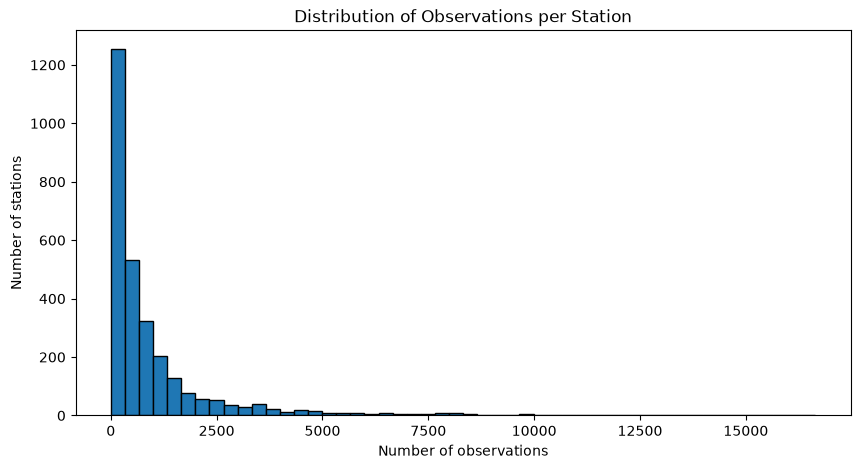

In [32]:
status_counts = (
    status_clean.groupby("station_id")
    .size()
    .rename("observation_count")
)

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(status_counts, bins=50, edgecolor="black")

plt.title("Distribution of Observations per Station")
plt.xlabel("Number of observations")
plt.ylabel("Number of stations")

plt.show()

In [33]:

status_clean["time_utc"] = pd.to_datetime(
    status_clean["time"],
    unit="s",
    utc=True
)


coverage = (
    status_clean.groupby("station_id")
    .agg(
        observation_count=("time", "count"),
        first_observation=("time_utc", "min"),
        last_observation=("time_utc", "max")
    )
)

coverage["coverage_days"] = (
    coverage["last_observation"] -
    coverage["first_observation"]
).dt.total_seconds() / 86400

display(coverage.describe())

,observation_count,coverage_days
count,2899.000000,2899.000000
mean,1009.302173,256.687789
std,1678.189339,103.496037
min,1.000000,0.000000
25%,159.000000,177.880556
50%,427.000000,320.136806
75%,1099.500000,322.811806
max,16643.000000,323.297917


In [34]:
print("Stations with fewer than 50 observations:",
      (coverage["observation_count"] < 50).sum())

print("Stations with fewer than 100 observations:",
      (coverage["observation_count"] < 100).sum())

print("Stations with more than 1000 observations:",
      (coverage["observation_count"] > 1000).sum())

print("Stations with less than 7 days of coverage:",
      (coverage["coverage_days"] < 7).sum())

Stations with fewer than 50 observations: 296
Stations with fewer than 100 observations: 492
Stations with more than 1000 observations: 789
Stations with less than 7 days of coverage: 35


In [35]:

zero_ids = set(zero_capacity["id"])

zero_status = status_clean[
    status_clean["station_id"].isin(zero_ids)
]

print("Status observations for zero-capacity stations:",
      len(zero_status))

print("Average bikes available:",
      zero_status["bikes_available_to_rent"].mean())

print("Maximum bikes available:",
      zero_status["bikes_available_to_rent"].max())

print("Average total bikes:",
      zero_status["bikes"].mean())

Status observations for zero-capacity stations: 735337
Average bikes available: 5.257707690487491
Maximum bikes available: 189
Average total bikes: 5.342453868090413


Feature Engineering

We aggregate the station status observations using the station identifier.

Statistical measures such as mean, standard deviation, minimum and maximum availability help describe the typical behaviour and variability of each station.

Each station will have one row in the resulting feature dataset.

In [36]:
station_features = (
    status_clean.groupby("station_id")
    .agg(
        avg_bikes_available=("bikes_available_to_rent", "mean"),
        std_bikes_available=("bikes_available_to_rent", "std"),
        min_bikes_available=("bikes_available_to_rent", "min"),
        max_bikes_available=("bikes_available_to_rent", "max"),

        avg_bikes=("bikes", "mean"),
        avg_booked_bikes=("booked_bikes", "mean"),
        avg_free_racks=("free_racks", "mean"),
        avg_free_special_racks=("free_special_racks", "mean"),

        maintenance_ratio=("maintenance", "mean"),
        observation_count=("time", "count")
    )
    .reset_index()
)

display(station_features.head())
print("Station feature shape:", station_features.shape)

,station_id,avg_bikes_available,std_bikes_available,min_bikes_available,max_bikes_available,avg_bikes,avg_booked_bikes,avg_free_racks,avg_free_special_racks,maintenance_ratio,observation_count
0,94,3.707865,1.582592,0,7,3.887640,0.179775,0.0,0.0,0.0,89
1,522,3.246269,1.657743,0,9,3.369403,0.123134,0.0,0.0,0.0,268
2,556,4.016502,1.738651,0,10,4.033003,0.016502,0.0,0.0,0.0,303
3,568,2.863636,1.595666,0,7,2.969697,0.106061,0.0,0.0,0.0,132
4,572,3.950820,2.028351,0,9,3.950820,0.000000,0.0,0.0,0.0,61


Station feature shape: (2899, 11)


In [37]:
coverage_features = coverage[
    ["coverage_days"]
].reset_index()

station_features = station_features.merge(
    coverage_features,
    on="station_id",
    how="left"
)

print("Updated shape:", station_features.shape)

Updated shape: (2899, 12)


In [38]:
station_features = station_features.merge(
    stations_clean,
    left_on="station_id",
    right_on="id",
    how="left"
)

cities_info = cities_clean[
    ["id", "name", "country", "timezone"]
].rename(columns={
    "id": "city_id",
    "name": "city_name"
})

station_features = station_features.merge(
    cities_info,
    on="city_id",
    how="left"
)

print("Final station dataset shape:", station_features.shape)

display(station_features.head())

Final station dataset shape: (2899, 26)


,station_id,avg_bikes_available,std_bikes_available,min_bikes_available,max_bikes_available,avg_bikes,avg_booked_bikes,avg_free_racks,avg_free_special_racks,maintenance_ratio,...,terminal_type,place_type,bike_racks,special_racks,lon,lat,total_capacity,city_name,country,timezone
0,94,3.707865,1.582592,0,7,3.887640,0.179775,0.0,0.0,0.0,...,NaN,0,0,0,16.698299,47.906200,0,Neusiedler See,AT,Europe/Berlin
1,522,3.246269,1.657743,0,9,3.369403,0.123134,0.0,0.0,0.0,...,NaN,0,0,0,16.846504,47.942251,0,Neusiedler See,AT,Europe/Berlin
2,556,4.016502,1.738651,0,10,4.033003,0.016502,0.0,0.0,0.0,...,NaN,8,0,0,16.834939,47.928737,0,Neusiedler See,AT,Europe/Berlin
3,568,2.863636,1.595666,0,7,2.969697,0.106061,0.0,0.0,0.0,...,NaN,0,0,0,16.746265,47.941338,0,Neusiedler See,AT,Europe/Berlin
4,572,3.950820,2.028351,0,9,3.950820,0.000000,0.0,0.0,0.0,...,NaN,0,0,0,16.697245,47.754617,0,Neusiedler See,AT,Europe/Berlin


In [39]:
station_features["availability_ratio"] = (
    station_features["avg_bikes_available"] /
    station_features["total_capacity"].replace(0, np.nan)
)

print("Missing availability ratios:",
      station_features["availability_ratio"].isna().sum())

display(
    station_features[
        ["station_id", "total_capacity",
         "avg_bikes_available", "availability_ratio"]
    ].head(10)
)

Missing availability ratios: 1204


,station_id,total_capacity,avg_bikes_available,availability_ratio
0,94,0,3.707865,NaN
1,522,0,3.246269,NaN
2,556,0,4.016502,NaN
3,568,0,2.863636,NaN
4,572,0,3.950820,NaN
5,744,0,3.400000,NaN
6,1450,0,5.319588,NaN
7,1452,0,4.862385,NaN
8,3401,0,3.392157,NaN
9,3403,0,3.000000,NaN


In [40]:
print("Number of stations:", station_features["station_id"].nunique())

print("\nMissing values:")
display(
    station_features.isna().sum().sort_values(ascending=False).head(15)
)

print("\nFeature statistics:")
display(
    station_features[
        [
            "avg_bikes_available",
            "std_bikes_available",
            "avg_bikes",
            "avg_free_racks",
            "maintenance_ratio",
            "observation_count",
            "coverage_days",
            "total_capacity",
            "availability_ratio"
        ]
    ].describe()
)

Number of stations: 2899

Missing values:


availability_ratio     1204
terminal_type           577
std_bikes_available       7
name                      0
timezone                  0
country                   0
city_name                 0
total_capacity            0
lat                       0
lon                       0
special_racks             0
bike_racks                0
place_type                0
app_number                0
station_id                0
dtype: int64


Feature statistics:


,avg_bikes_available,std_bikes_available,avg_bikes,avg_free_racks,maintenance_ratio,observation_count,coverage_days,total_capacity,availability_ratio
count,2899.000000,2892.000000,2899.000000,2899.000000,2899.000000,2899.000000,2899.000000,2899.000000,1695.000000
mean,4.625957,2.334192,4.652482,3.136500,0.028330,1009.302173,256.687789,6.031045,0.571703
std,4.110785,1.345135,4.102000,3.996085,0.164759,1678.189339,103.496037,6.488170,0.374031
min,0.000000,0.500000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,2.540398,1.533142,2.563033,0.000000,0.000000,159.000000,177.880556,0.000000,0.375387
50%,3.883465,2.101151,3.891365,1.788252,0.000000,427.000000,320.136806,5.000000,0.532878
75%,5.957143,2.851204,5.973322,5.299959,0.000000,1099.500000,322.811806,10.000000,0.670397
max,102.818898,36.247332,102.818898,62.468750,1.000000,16643.000000,323.297917,70.000000,6.486188




We examine stations where average bike availability exceeds their reported infrastructure capacity.



In [41]:
# Stations with a valid positive reported capacity
valid_capacity = station_features[
    station_features["total_capacity"] > 0
]

# Count stations where availability exceeds capacity
inconsistent_stations = valid_capacity[
    valid_capacity["availability_ratio"] > 1
]

print("Stations with positive capacity:", len(valid_capacity))

print("Stations where availability exceeds capacity:",
      len(inconsistent_stations))

print("Percentage:",
      round(len(inconsistent_stations) / len(valid_capacity) * 100, 2),
      "%")

display(
    inconsistent_stations[
        ["station_id", "name", "total_capacity",
         "avg_bikes_available", "availability_ratio"]
    ].head(10)
)

Stations with positive capacity: 1695
Stations where availability exceeds capacity: 112
Percentage: 6.61 %


,station_id,name,total_capacity,avg_bikes_available,availability_ratio
96,45886,LIDL Dzelzavas iela 75B,5,5.677650,1.135530
135,50473,Auf der Wenge / Sankt-Jörgen-Platz,4,5.950000,1.487500
138,50477,Stadtmitte / Leineweberstr.,10,12.714899,1.271490
139,50478,Wertgasse,6,7.909269,1.318211
191,65937,Ferienwohnanlage `Alte Molkerei` Liepe 5533,15,20.155556,1.343704
194,66080,Fahrradverleih Hertel Trassenheide 5503,6,7.271028,1.211838
200,66388,Naturcamping Lütow 5508,20,27.180328,1.359016
204,66394,Camping Am Sandfeld Koserow 5514,6,10.625000,1.770833
205,66395,Strandhotel Seerose Kölpinsee 5515,5,20.573034,4.114607
206,66397,Zweirad - Awe Strandpromenade Ückeritz 5516,18,102.818898,5.712161


Station Activity and Availability Changes

We examine consecutive station status observations to understand how bike availability evolves over time.



In [42]:

activity = status_clean.sort_values(
    ["station_id", "time_utc"]
).copy()


activity["bike_change"] = (
    activity.groupby("station_id")["bikes_available_to_rent"]
    .diff()
)


activity["interval_hours"] = (
    activity.groupby("station_id")["time_utc"]
    .diff()
    .dt.total_seconds() / 3600
)

# Absolute change
activity["absolute_change"] = activity["bike_change"].abs()

display(
    activity[
        ["station_id", "time_utc",
         "bikes_available_to_rent",
         "bike_change", "interval_hours"]
    ].head(15)
)

,station_id,time_utc,bikes_available_to_rent,bike_change,interval_hours
42878,94,2022-08-29 13:12:01+00:00,5,NaN,NaN
42902,94,2022-08-29 13:13:01+00:00,4,-1.0,0.016667
59129,94,2022-08-30 13:30:01+00:00,5,1.0,24.283333
81722,94,2022-08-31 17:57:01+00:00,4,-1.0,28.450000
81875,94,2022-08-31 18:05:01+00:00,5,1.0,0.133333
144056,94,2022-09-04 15:38:01+00:00,6,1.0,93.550000
144072,94,2022-09-04 15:39:01+00:00,7,1.0,0.016667
152431,94,2022-09-05 08:32:01+00:00,6,-1.0,16.883333
152453,94,2022-09-05 08:34:01+00:00,5,-1.0,0.033333
152752,94,2022-09-05 08:59:01+00:00,4,-1.0,0.416667


In [43]:
print("Observation interval statistics (hours):")

display(activity["interval_hours"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
))

Observation interval statistics (hours):


count    2.923068e+06
mean     6.109782e+00
std      5.694825e+01
min      1.333333e-02
25%      6.666667e-02
50%      4.666667e-01
75%      2.633333e+00
90%      1.203333e+01
95%      2.158333e+01
max      6.912267e+03
Name: interval_hours, dtype: float64

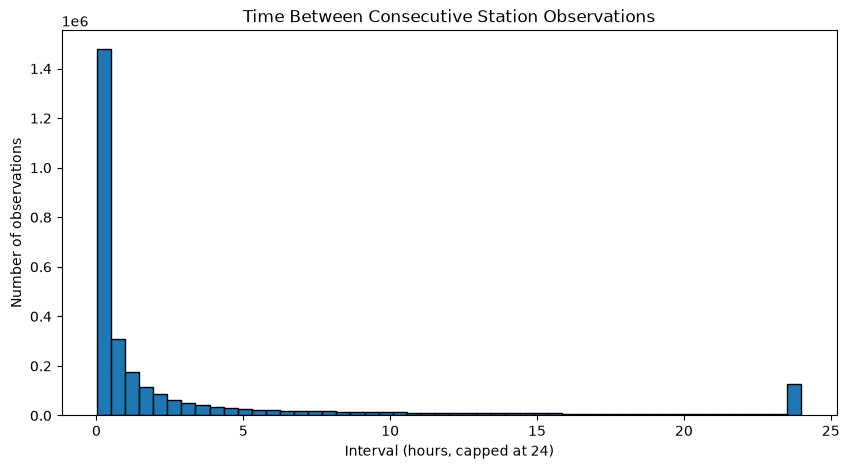

In [44]:
plt.figure(figsize=(10, 5))

plt.hist(
    activity["interval_hours"].dropna().clip(upper=24),
    bins=50,
    edgecolor="black"
)

plt.title("Time Between Consecutive Station Observations")
plt.xlabel("Interval (hours, capped at 24)")
plt.ylabel("Number of observations")

plt.show()

In [45]:


thresholds = [1, 3, 6, 12, 24]

for hours in thresholds:
    valid = activity["interval_hours"].between(
        0, hours, inclusive="right"
    )

    print(
        f"Up to {hours:2} hours: "
        f"{valid.sum():,} observations "
        f"({valid.mean() * 100:.2f}%)"
    )

Up to  1 hours: 1,803,042 observations (61.62%)
Up to  3 hours: 2,238,455 observations (76.50%)
Up to  6 hours: 2,443,482 observations (83.51%)
Up to 12 hours: 2,630,336 observations (89.90%)
Up to 24 hours: 2,799,447 observations (95.68%)


In [46]:
# Keep valid consecutive observations within 6 hours
activity_filtered = activity[
    (activity["interval_hours"] > 0) &
    (activity["interval_hours"] <= 6)
].copy()

print("Original observations:", len(activity))
print("Filtered observations:", len(activity_filtered))
print("Retained percentage:",
      round(len(activity_filtered) / len(activity) * 100, 2), "%")

Original observations: 2925967
Filtered observations: 2443482
Retained percentage: 83.51 %


In [47]:
# Separate increases and decreases
activity_filtered["bike_increase"] = (
    activity_filtered["bike_change"].clip(lower=0)
)

activity_filtered["bike_decrease"] = (
    -activity_filtered["bike_change"].clip(upper=0)
)

# Absolute change per hour
activity_filtered["change_per_hour"] = (
    activity_filtered["absolute_change"] /
    activity_filtered["interval_hours"]
)

# Aggregate activity by station
activity_features = (
    activity_filtered.groupby("station_id")
    .agg(
        mean_abs_change=("absolute_change", "mean"),
        mean_increase=("bike_increase", "mean"),
        mean_decrease=("bike_decrease", "mean"),
        median_change_per_hour=("change_per_hour", "median"),
        activity_std=("bike_change", "std"),
        activity_observations=("bike_change", "count")
    )
    .reset_index()
)

display(activity_features.head())

print("Activity feature shape:", activity_features.shape)

,station_id,mean_abs_change,mean_increase,mean_decrease,median_change_per_hour,activity_std,activity_observations
0,94,1.196429,0.678571,0.517857,30.000000,1.290198,56
1,522,1.193939,0.642424,0.551515,7.058824,1.296422,165
2,556,1.150943,0.580189,0.570755,20.000000,1.215970,212
3,568,1.074074,0.654321,0.419753,20.000000,1.164813,81
4,572,1.184211,0.605263,0.578947,15.000000,1.262491,38


Activity feature shape: (2876, 7)


In [48]:
station_features = station_features.merge(
    activity_features,
    on="station_id",
    how="left"
)

print("Updated station dataset:", station_features.shape)

display(
    station_features[
        [
            "station_id",
            "avg_bikes_available",
            "mean_abs_change",
            "mean_increase",
            "mean_decrease",
            "median_change_per_hour"
        ]
    ].head(10)
)

Updated station dataset: (2899, 33)


,station_id,avg_bikes_available,mean_abs_change,mean_increase,mean_decrease,median_change_per_hour
0,94,3.707865,1.196429,0.678571,0.517857,30.000000
1,522,3.246269,1.193939,0.642424,0.551515,7.058824
2,556,4.016502,1.150943,0.580189,0.570755,20.000000
3,568,2.863636,1.074074,0.654321,0.419753,20.000000
4,572,3.950820,1.184211,0.605263,0.578947,15.000000
5,744,3.400000,1.228571,0.728571,0.500000,25.000000
6,1450,5.319588,1.265092,0.703412,0.561680,6.666667
7,1452,4.862385,1.156250,0.593750,0.562500,20.000000
8,3401,3.392157,1.120000,0.880000,0.240000,3.529412
9,3403,3.000000,1.040000,0.680000,0.360000,20.000000


In [49]:
activity_columns = [
    "mean_abs_change",
    "mean_increase",
    "mean_decrease",
    "median_change_per_hour",
    "activity_std",
    "activity_observations"
]

display(station_features[activity_columns].isna().sum())

mean_abs_change           23
mean_increase             23
mean_decrease             23
median_change_per_hour    23
activity_std              48
activity_observations     23
dtype: int64

In [50]:
print("Stations with no activity observations:",
      station_features["activity_observations"].isna().sum())

print("Stations with only one activity observation:",
      (station_features["activity_observations"] == 1).sum())

print("Activity observation statistics:")
display(station_features["activity_observations"].describe())

Stations with no activity observations: 23
Stations with only one activity observation: 25
Activity observation statistics:


count     2876.000000
mean       849.611266
std       1648.671361
min          1.000000
25%         78.750000
50%        256.000000
75%        825.000000
max      16490.000000
Name: activity_observations, dtype: float64

In [51]:
display(
    activity_filtered["change_per_hour"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

count    2.443482e+06
mean     1.516282e+01
std      2.786068e+01
min      0.000000e+00
25%      6.122449e-01
50%      2.608696e+00
75%      2.000000e+01
90%      6.000000e+01
95%      6.000000e+01
99%      1.200000e+02
max      5.400000e+03
Name: change_per_hour, dtype: float64

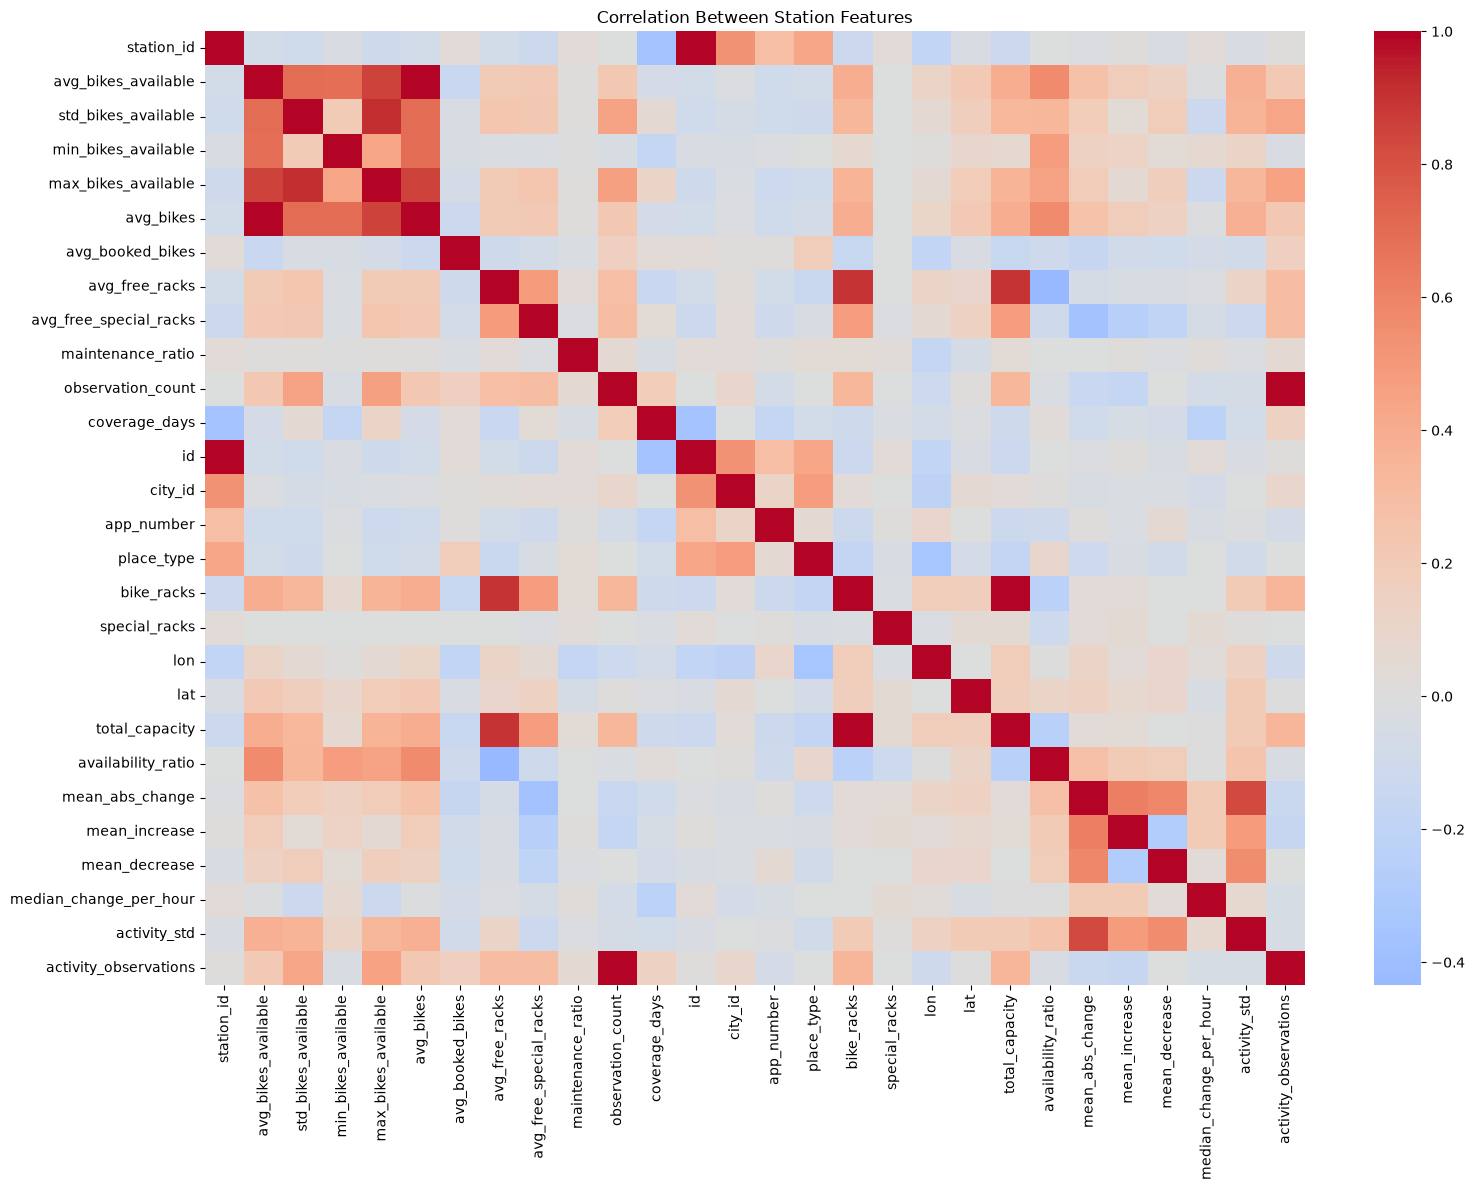

In [52]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_features = station_features.select_dtypes(
    include="number"
)

correlation = numeric_features.corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Correlation Between Station Features")
plt.tight_layout()
plt.show()

In [53]:
features = [
    "avg_bikes_available",
    "std_bikes_available",
    "min_bikes_available",
    "max_bikes_available",
    "avg_booked_bikes",
    "avg_free_racks",
    "avg_free_special_racks",
    "maintenance_ratio",
    "total_capacity",
    "mean_abs_change",
    "mean_increase",
    "median_change_per_hour",
    "activity_std"
]

X = station_features[features].copy()

print("Initial feature shape:", X.shape)

Initial feature shape: (2899, 13)


In [54]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")

X_imputed = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns,
    index=X.index
)

print("Missing values after imputation:")
print(X_imputed.isna().sum().sum())

print("Final shape:", X_imputed.shape)

Missing values after imputation:
0
Final shape: (2899, 13)


In [55]:
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()

X_scaled = scaler.fit_transform(X_imputed)

print("Scaled dataset shape:", X_scaled.shape)

Scaled dataset shape: (2899, 13)


In [56]:
from sklearn.decomposition import PCA

pca = PCA()

X_pca = pca.fit_transform(X_scaled)

print("Original shape:", X_scaled.shape)
print("PCA shape:", X_pca.shape)

Original shape: (2899, 13)
PCA shape: (2899, 13)


In [57]:
explained_variance = pca.explained_variance_ratio_

cumulative_variance = explained_variance.cumsum()

for i in range(len(explained_variance)):
    print(
        f"PC{i+1}: "
        f"{explained_variance[i]*100:.2f}% | "
        f"Cumulative: {cumulative_variance[i]*100:.2f}%"
    )

PC1: 36.98% | Cumulative: 36.98%
PC2: 19.09% | Cumulative: 56.08%
PC3: 15.53% | Cumulative: 71.61%
PC4: 15.28% | Cumulative: 86.88%
PC5: 6.34% | Cumulative: 93.22%
PC6: 2.98% | Cumulative: 96.20%
PC7: 1.46% | Cumulative: 97.67%
PC8: 1.40% | Cumulative: 99.07%
PC9: 0.36% | Cumulative: 99.42%
PC10: 0.32% | Cumulative: 99.75%
PC11: 0.12% | Cumulative: 99.87%
PC12: 0.07% | Cumulative: 99.94%
PC13: 0.06% | Cumulative: 100.00%


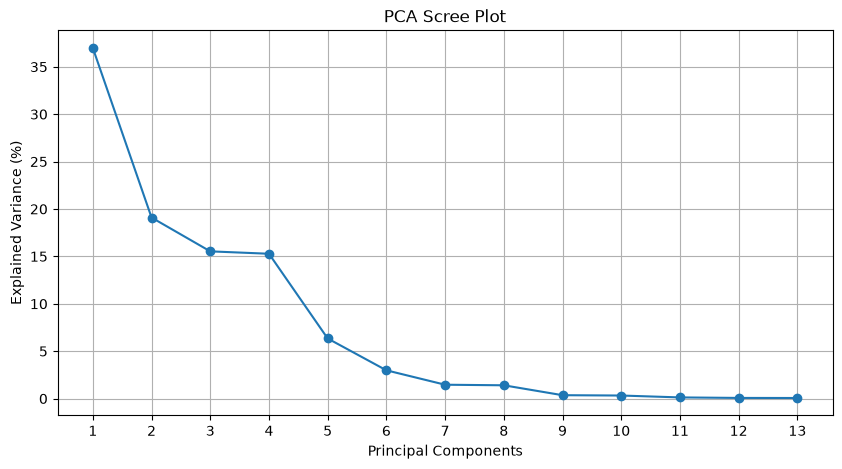

In [58]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance * 100,
    marker="o"
)

plt.xlabel("Principal Components")
plt.ylabel("Explained Variance (%)")
plt.title("PCA Scree Plot")
plt.xticks(range(1, 14))
plt.grid(True)

plt.show()

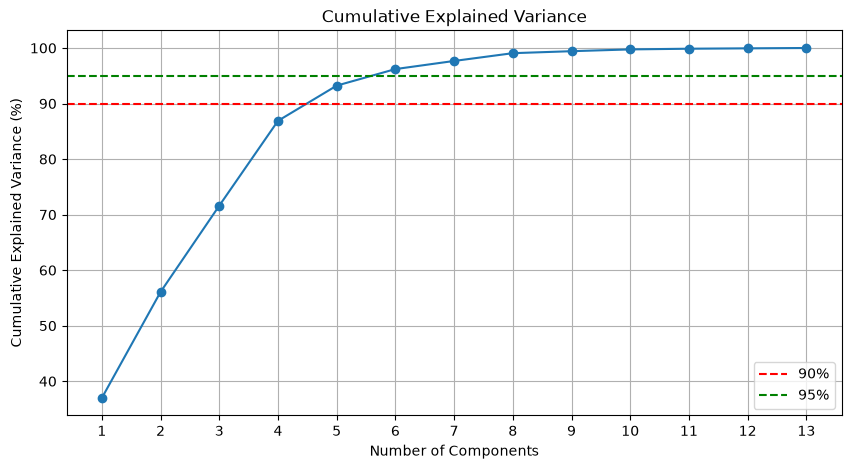

In [59]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance * 100,
    marker="o"
)

plt.axhline(y=90, color="red", linestyle="--", label="90%")
plt.axhline(y=95, color="green", linestyle="--", label="95%")

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("Cumulative Explained Variance")

plt.xticks(range(1, 14))
plt.legend()
plt.grid(True)

plt.show()

In [60]:
pca_final = PCA(n_components=5)

X_pca_final = pca_final.fit_transform(X_scaled)

print("Original dataset:", X_scaled.shape)
print("Reduced dataset:", X_pca_final.shape)

print(
    "Total variance retained:",
    round(sum(pca_final.explained_variance_ratio_) * 100, 2),
    "%"
)

Original dataset: (2899, 13)
Reduced dataset: (2899, 5)
Total variance retained: 93.22 %


In [61]:
loadings = pd.DataFrame(
    pca_final.components_.T,
    columns=[f"PC{i+1}" for i in range(5)],
    index=X_imputed.columns
)

display(loadings.round(3))

,PC1,PC2,PC3,PC4,PC5
avg_bikes_available,0.005,-0.231,-0.071,0.325,0.183
std_bikes_available,-0.033,-0.125,0.013,0.162,0.338
min_bikes_available,0.062,-0.288,-0.322,0.716,-0.433
max_bikes_available,-0.030,-0.161,-0.017,0.231,0.253
avg_booked_bikes,-0.090,0.785,0.297,0.521,0.113
avg_free_racks,-0.008,-0.090,0.117,0.021,0.111
avg_free_special_racks,-0.070,-0.426,0.820,0.141,0.037
maintenance_ratio,0.001,-0.001,-0.001,-0.000,-0.000
total_capacity,-0.001,-0.097,0.082,0.040,0.125
mean_abs_change,0.065,-0.027,-0.210,0.032,0.401


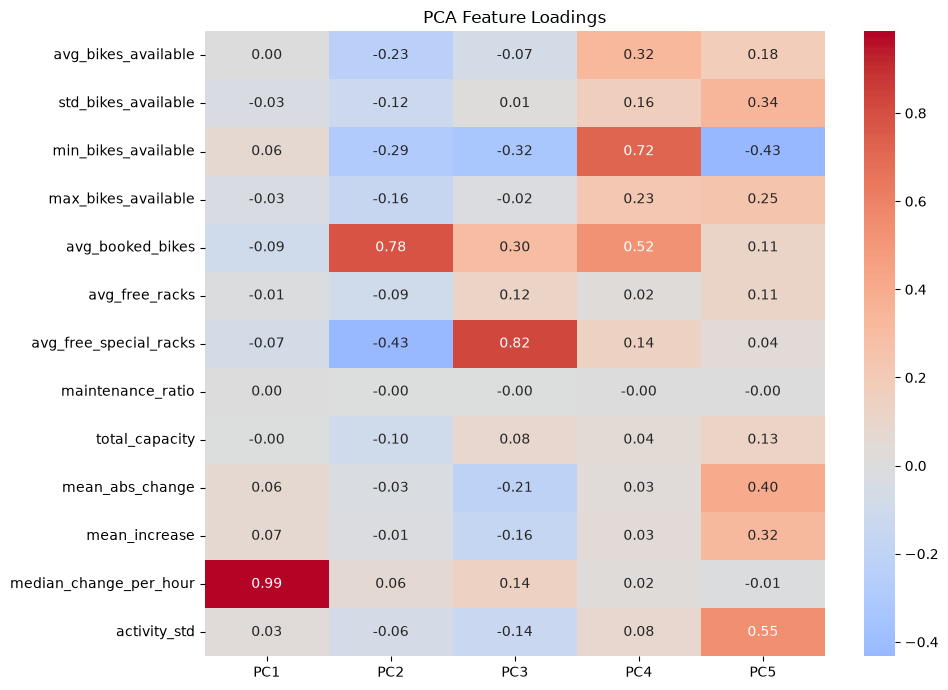

In [62]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    loadings,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("PCA Feature Loadings")
plt.tight_layout()
plt.show()

count    2876.000000
mean        5.349424
std        10.688116
min         0.000000
90%        15.000000
95%        30.000000
99%        60.000000
max       120.000000
Name: median_change_per_hour, dtype: float64

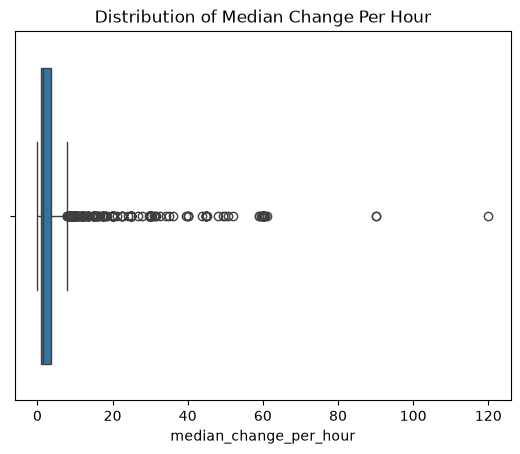

In [63]:
display(
    station_features["median_change_per_hour"].describe(
        percentiles=[0.90, 0.95, 0.99]
    )
)

sns.boxplot(
    x=station_features["median_change_per_hour"]
)

plt.title("Distribution of Median Change Per Hour")
plt.show()

In [64]:
# Inspect stations with the highest median change rates

display(
    station_features[
        [
            "station_id",
            "median_change_per_hour",
            "activity_observations",
            "mean_abs_change",
            "avg_bikes_available"
        ]
    ]
    .sort_values(
        "median_change_per_hour",
        ascending=False
    )
    .head(15)
)

,station_id,median_change_per_hour,activity_observations,mean_abs_change,avg_bikes_available
2337,77080269,120.000000,1.0,2.000000,1.750000
233,70252,90.000000,2.0,1.500000,3.222222
2891,209682764,90.000000,2.0,1.500000,1.000000
486,405837,61.016949,1.0,1.000000,1.352941
193,66072,60.508475,2.0,1.000000,3.400000
448,350568,60.508475,4.0,1.500000,3.000000
2491,101894419,60.000000,1.0,1.000000,0.500000
874,6495588,60.000000,11.0,0.818182,0.666667
102,46616,60.000000,51.0,1.039216,3.303922
258,99838,60.000000,13.0,1.538462,6.750000


In [65]:
station_features["median_change_log"] = np.log1p(
    station_features["median_change_per_hour"]
)

In [66]:
# Compare activity reliability

print("Stations with fewer than 5 observations:",
      (station_features["activity_observations"] < 5).sum())

print("Stations with fewer than 10 observations:",
      (station_features["activity_observations"] < 10).sum())

print("Stations with fewer than 20 observations:",
      (station_features["activity_observations"] < 20).sum())

print("Stations with at least 20 observations:",
      (station_features["activity_observations"] >= 20).sum())

Stations with fewer than 5 observations: 84
Stations with fewer than 10 observations: 162
Stations with fewer than 20 observations: 266
Stations with at least 20 observations: 2610


In [67]:
reliable_stations = station_features[
    station_features["activity_observations"] >= 20
]

display(
    reliable_stations[
        [
            "station_id",
            "median_change_per_hour",
            "activity_observations",
            "mean_abs_change",
            "avg_bikes_available"
        ]
    ]
    .sort_values(
        "median_change_per_hour",
        ascending=False
    )
    .head(15)
)


,station_id,median_change_per_hour,activity_observations,mean_abs_change,avg_bikes_available
2896,214585310,60.0,137.0,1.875912,17.031447
2593,110456278,60.0,239.0,1.050209,4.480106
1110,10279583,60.0,106.0,1.471698,7.343137
68,42863,60.0,27.0,1.259259,1.614035
1428,20060094,60.0,25.0,1.120000,2.613333
1446,25064377,60.0,57.0,1.070175,3.019417
337,187151,60.0,132.0,1.075758,3.334928
283,113453,60.0,71.0,0.971831,2.459627
2588,110455621,60.0,127.0,1.023622,4.100437
2591,110456006,60.0,41.0,1.097561,3.511111


In [68]:
station_features["median_change_log"] = np.log1p(
    station_features["median_change_per_hour"]
)

In [69]:

X_log = X.copy()


X_log["median_change_per_hour"] = np.log1p(
    X_log["median_change_per_hour"]
)

In [70]:

station_id = 10279583

station_activity = (
    activity_filtered[
        activity_filtered["station_id"] == station_id
    ]
    .sort_values("time_utc")
    .copy()
)

display(
    station_activity[
        [
            "time_utc",
            "bikes_available_to_rent",
            "bike_change",
            "interval_hours",
            "change_per_hour"
        ]
    ].head(20)
)

,time_utc,bikes_available_to_rent,bike_change,interval_hours,change_per_hour
95629,2022-09-01 13:49:01+00:00,8,2.0,0.050000,40.000000
297640,2022-09-15 21:00:01+00:00,7,2.0,0.033333,60.000000
298354,2022-09-16 01:01:01+00:00,6,-1.0,4.016667,0.248963
298355,2022-09-16 01:02:01+00:00,7,1.0,0.016667,60.000000
333272,2022-09-21 01:22:01+00:00,7,2.0,0.016667,120.000000
385873,2022-09-25 00:26:01+00:00,7,1.0,0.016667,60.000000
385890,2022-09-25 00:29:01+00:00,6,-1.0,0.050000,20.000000
386641,2022-09-25 05:26:01+00:00,7,1.0,4.950000,0.202020
425908,2022-09-28 13:04:01+00:00,7,-3.0,3.966667,0.756303
456439,2022-09-30 23:30:01+00:00,7,-3.0,2.550000,1.176471


In [71]:
print("Interval statistics (minutes):")

display(
    (station_activity["interval_hours"] * 60).describe()
)

print("Bike change distribution:")

display(
    station_activity["bike_change"].value_counts()
)

Interval statistics (minutes):


count    106.000000
mean      40.311635
std       79.397076
min        1.000000
25%        1.000000
50%        2.000000
75%       29.754167
max      329.000000
Name: interval_hours, dtype: float64

Bike change distribution:


bike_change
 1.0    67
-1.0    17
 2.0     6
 3.0     4
-2.0     3
-3.0     2
-4.0     2
 5.0     2
 6.0     2
-6.0     1
Name: count, dtype: int64

In [72]:
# Calculate alternative activity measures

valid = station_activity[
    (station_activity["interval_hours"] > 0) &
    (station_activity["interval_hours"] <= 6)
].copy()

median_rate = valid["change_per_hour"].median()

aggregate_rate = (
    valid["bike_change"].abs().sum() /
    valid["interval_hours"].sum()
)

print("Median hourly change rate:", median_rate)
print("Aggregate hourly change rate:", aggregate_rate)

print("Total observations:", len(valid))
print("Total absolute bike changes:", valid["bike_change"].abs().sum())
print("Total observed hours:", valid["interval_hours"].sum())

Median hourly change rate: 60.0
Aggregate hourly change rate: 2.1904813910492935
Total observations: 106
Total absolute bike changes: 156.0
Total observed hours: 71.21722222222223


In [73]:
interval_minutes = activity_filtered["interval_hours"] * 60

for minutes in [1, 2, 5, 10, 30]:
    count = (interval_minutes <= minutes).sum()

    print(
        f"Intervals up to {minutes} minutes:",
        count,
        f"({count / len(activity_filtered) * 100:.2f}%)"
    )

Intervals up to 1 minutes: 345854 (14.15%)
Intervals up to 2 minutes: 512230 (20.96%)
Intervals up to 5 minutes: 794627 (32.52%)
Intervals up to 10 minutes: 1033403 (42.29%)
Intervals up to 30 minutes: 1494879 (61.18%)


In [74]:
# Calculate aggregate activity rate for each station

aggregate_activity = (
    activity_filtered
    .groupby("station_id")
    .agg(
        total_bike_changes=(
            "bike_change",
            lambda x: x.abs().sum()
        ),
        total_observed_hours=(
            "interval_hours",
            "sum"
        ),
        activity_observations=(
            "bike_change",
            "count"
        )
    )
    .reset_index()
)

# Calculate aggregate hourly change rate

aggregate_activity["aggregate_change_per_hour"] = (
    aggregate_activity["total_bike_changes"] /
    aggregate_activity["total_observed_hours"]
)

display(
    aggregate_activity[
        [
            "station_id",
            "total_bike_changes",
            "total_observed_hours",
            "aggregate_change_per_hour",
            "activity_observations"
        ]
    ].head(10)
)

print("Aggregate rate statistics:")

display(
    aggregate_activity["aggregate_change_per_hour"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

,station_id,total_bike_changes,total_observed_hours,aggregate_change_per_hour,activity_observations
0,94,67.0,35.350000,1.895332,56
1,522,197.0,163.067222,1.208091,165
2,556,244.0,182.149722,1.339557,212
3,568,87.0,38.032778,2.287501,81
4,572,45.0,27.566667,1.632406,38
5,744,86.0,36.566667,2.351869,70
6,1450,482.0,294.166944,1.638525,381
7,1452,74.0,63.800278,1.159870,64
8,3401,28.0,25.783611,1.085961,25
9,3403,26.0,12.133056,2.142906,25


Aggregate rate statistics:


count    2876.000000
mean        1.687998
std         5.756685
min         0.000000
25%         0.712237
50%         0.898119
75%         1.276388
90%         1.937106
95%         2.736192
99%        15.114871
max       120.000000
Name: aggregate_change_per_hour, dtype: float64

In [75]:
# Compare old and new activity measures

comparison = station_features[
    ["station_id", "median_change_per_hour"]
].merge(
    aggregate_activity[
        ["station_id", "aggregate_change_per_hour"]
    ],
    on="station_id",
    how="left"
)

display(comparison.describe())

print(
    "Correlation:",
    comparison[
        [
            "median_change_per_hour",
            "aggregate_change_per_hour"
        ]
    ].corr().iloc[0, 1]
)

,station_id,median_change_per_hour,aggregate_change_per_hour
count,2.899000e+03,2876.000000,2876.000000
mean,4.077844e+07,5.349424,1.687998
std,4.718919e+07,10.688116,5.756685
min,9.400000e+01,0.000000,0.000000
25%,4.682712e+06,0.991803,0.712237
50%,2.531344e+07,1.538352,0.898119
75%,5.660614e+07,3.750000,1.276388
max,2.192360e+08,120.000000,120.000000


Correlation: 0.5759400814466631


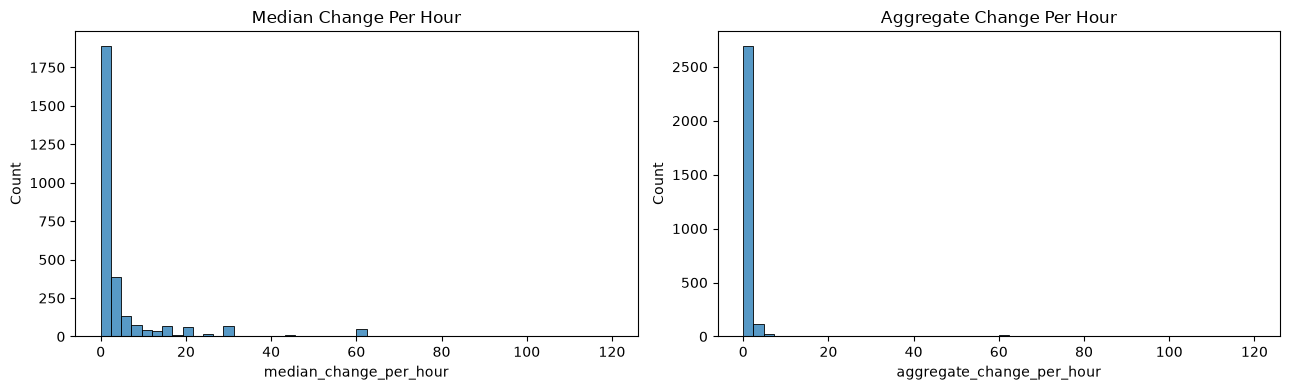

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    comparison["median_change_per_hour"],
    bins=50,
    ax=axes[0]
)

axes[0].set_title("Median Change Per Hour")

sns.histplot(
    comparison["aggregate_change_per_hour"],
    bins=50,
    ax=axes[1]
)

axes[1].set_title("Aggregate Change Per Hour")

plt.tight_layout()
plt.show()

In [77]:
station_features = station_features.merge(
    aggregate_activity[
        ["station_id", "aggregate_change_per_hour"]
    ],
    on="station_id",
    how="left",
    validate="one_to_one"
)

print("Missing aggregate rates:")
print(
    station_features["aggregate_change_per_hour"].isna().sum()
)

print("Updated shape:", station_features.shape)

Missing aggregate rates:
23
Updated shape: (2899, 35)


In [78]:
station_features["aggregate_change_log"] = np.log1p(
    station_features["aggregate_change_per_hour"]
)

display(
    station_features[
        [
            "aggregate_change_per_hour",
            "aggregate_change_log"
        ]
    ].describe()
)

,aggregate_change_per_hour,aggregate_change_log
count,2876.000000,2876.000000
mean,1.687998,0.750912
std,5.756685,0.428394
min,0.000000,0.000000
25%,0.712237,0.537801
50%,0.898119,0.640863
75%,1.276388,0.822590
max,120.000000,4.795791


In [79]:
display(
    station_features.nlargest(
        15,
        "aggregate_change_per_hour"
    )[
        [
            "station_id",
            "aggregate_change_per_hour",
            "activity_observations",
            "avg_bikes_available"
        ]
    ]
)

,station_id,aggregate_change_per_hour,activity_observations,avg_bikes_available
2337,77080269,120.000000,1.0,1.750000
233,70252,90.000000,2.0,3.222222
2891,209682764,90.000000,2.0,1.000000
486,405837,61.016949,1.0,1.352941
193,66072,60.504202,2.0,3.400000
208,66402,60.000000,1.0,5.000000
305,132838,60.000000,1.0,7.250000
483,405829,60.000000,2.0,0.764706
493,407022,60.000000,1.0,1.250000
882,6495610,60.000000,1.0,0.500000


In [80]:
print("Activity observation distribution:")

display(
    station_features["activity_observations"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90]
    )
)

for minimum in [5, 10, 20, 30]:
    valid = station_features[
        station_features["activity_observations"] >= minimum
    ]

    print(
        f"Minimum {minimum} observations:",
        len(valid),
        f"({len(valid) / len(station_features) * 100:.2f}%)"
    )

Activity observation distribution:


count     2876.000000
mean       849.611266
std       1648.671361
min          1.000000
25%         78.750000
50%        256.000000
75%        825.000000
90%       2278.500000
max      16490.000000
Name: activity_observations, dtype: float64

Minimum 5 observations: 2792 (96.31%)
Minimum 10 observations: 2714 (93.62%)
Minimum 20 observations: 2610 (90.03%)
Minimum 30 observations: 2515 (86.75%)


In [81]:
station_features["reliable_aggregate_rate"] = (
    station_features["aggregate_change_per_hour"].where(
        station_features["activity_observations"] >= 10
    )
)

print("Missing reliable activity rates:")
print(
    station_features["reliable_aggregate_rate"].isna().sum()
)

Missing reliable activity rates:
185


In [82]:
print("Stations with no activity:")
print(
    (station_features["activity_observations"] == 0).sum()
)

print("Stations with 1-9 observations:")
print(
    (
        (station_features["activity_observations"] > 0) &
        (station_features["activity_observations"] < 10)
    ).sum()
)

print("Stations with at least 10 observations:")
print(
    (station_features["activity_observations"] >= 10).sum()
)

Stations with no activity:
0
Stations with 1-9 observations:
162
Stations with at least 10 observations:
2714


In [83]:
for minimum in [5, 10, 20, 30]:

    valid = station_features[
        station_features["activity_observations"] >= minimum
    ]

    print(f"\nMinimum observations: {minimum}")

    print(
        valid["aggregate_change_per_hour"].describe(
            percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
        )
    )
    


Minimum observations: 5
count    2792.000000
mean        1.148616
std         1.149069
min         0.326081
50%         0.894137
75%         1.241936
90%         1.829233
95%         2.380361
99%         4.533162
max        38.785504
Name: aggregate_change_per_hour, dtype: float64

Minimum observations: 10
count    2714.000000
mean        1.111871
std         0.854974
min         0.358851
50%         0.888759
75%         1.229091
90%         1.779381
95%         2.298470
99%         3.906054
max        16.228795
Name: aggregate_change_per_hour, dtype: float64

Minimum observations: 20
count    2610.000000
mean        1.098157
std         0.812510
min         0.358851
50%         0.882728
75%         1.213409
90%         1.754452
95%         2.245492
99%         3.849510
max        16.228795
Name: aggregate_change_per_hour, dtype: float64

Minimum observations: 30
count    2515.000000
mean        1.090810
std         0.814668
min         0.358851
50%         0.875571
75%         1.2053

In [84]:
print("Missing activity observations:")
print(
    station_features["activity_observations"].isna().sum()
)

print("Zero activity observations:")
print(
    (station_features["activity_observations"] == 0).sum()
)

Missing activity observations:
23
Zero activity observations:
0


In [85]:
threshold_results = []

for minimum in [5, 10, 20, 30]:

    valid = station_features[
        station_features["activity_observations"] >= minimum
    ]["aggregate_change_per_hour"]

    threshold_results.append({
        "minimum_observations": minimum,
        "stations_retained": len(valid),
        "retention_percentage": round(
            len(valid) / len(station_features) * 100, 2
        ),
        "mean": valid.mean(),
        "median": valid.median(),
        "95th_percentile": valid.quantile(0.95),
        "99th_percentile": valid.quantile(0.99),
        "maximum": valid.max()
    })

threshold_comparison = pd.DataFrame(threshold_results)

display(threshold_comparison.round(3))

,minimum_observations,stations_retained,retention_percentage,mean,median,95th_percentile,99th_percentile,maximum
0,5,2792,96.31,1.149,0.894,2.380,4.533,38.786
1,10,2714,93.62,1.112,0.889,2.298,3.906,16.229
2,20,2610,90.03,1.098,0.883,2.245,3.850,16.229
3,30,2515,86.75,1.091,0.876,2.233,3.847,16.229


Aggregate activity was calculated using the total absolute changes in bicycle availability divided by the total observed time for each station. Stations with fewer than 10 activity observations were considered insufficiently observed for reliable activity-rate estimation. This threshold retained approximately 93.62% of stations. Preliminary comparisons showed that the threshold reduced extreme activity values while maintaining a similar median, suggesting improved robustness.

In [86]:

station_features["has_reliable_activity"] = (
    station_features["activity_observations"] >= 10
).astype(int)

print("Reliable stations:")
print(station_features["has_reliable_activity"].sum())

print("Unreliable stations:")
print(
    (station_features["has_reliable_activity"] == 0).sum()
)

Reliable stations:
2714
Unreliable stations:
185


In [87]:

activity_median = station_features["reliable_aggregate_rate"].median()

station_features["reliable_aggregate_rate"] = (
    station_features["reliable_aggregate_rate"]
    .fillna(activity_median)
)

print(
    station_features["reliable_aggregate_rate"].isna().sum()
)

0


In [88]:
# Inspect final station features

print("Dataset shape:", station_features.shape)

display(
    station_features[
        [
            "station_id",
            "avg_bikes_available",
            "total_capacity",
            "availability_ratio",
            "mean_abs_change",
            "mean_increase",
            "mean_decrease",
            "reliable_aggregate_rate",
            "activity_observations",
            "has_reliable_activity"
        ]
    ].head(10)
)

Dataset shape: (2899, 38)


,station_id,avg_bikes_available,total_capacity,availability_ratio,mean_abs_change,mean_increase,mean_decrease,reliable_aggregate_rate,activity_observations,has_reliable_activity
0,94,3.707865,0,NaN,1.196429,0.678571,0.517857,1.895332,56.0,1
1,522,3.246269,0,NaN,1.193939,0.642424,0.551515,1.208091,165.0,1
2,556,4.016502,0,NaN,1.150943,0.580189,0.570755,1.339557,212.0,1
3,568,2.863636,0,NaN,1.074074,0.654321,0.419753,2.287501,81.0,1
4,572,3.950820,0,NaN,1.184211,0.605263,0.578947,1.632406,38.0,1
5,744,3.400000,0,NaN,1.228571,0.728571,0.500000,2.351869,70.0,1
6,1450,5.319588,0,NaN,1.265092,0.703412,0.561680,1.638525,381.0,1
7,1452,4.862385,0,NaN,1.156250,0.593750,0.562500,1.159870,64.0,1
8,3401,3.392157,0,NaN,1.120000,0.880000,0.240000,1.085961,25.0,1
9,3403,3.000000,0,NaN,1.040000,0.680000,0.360000,2.142906,25.0,1


In [89]:
display(station_features.dtypes)

station_id                     int64
avg_bikes_available          float64
std_bikes_available          float64
min_bikes_available            int64
max_bikes_available            int64
avg_bikes                    float64
avg_booked_bikes             float64
avg_free_racks               float64
avg_free_special_racks       float64
maintenance_ratio            float64
observation_count              int64
coverage_days                float64
id                             int64
city_id                        int64
name                             str
app_number                     int64
terminal_type                    str
place_type                     int64
bike_racks                     int64
special_racks                  int64
lon                          float64
lat                          float64
total_capacity                 int64
city_name                        str
country                          str
timezone                         str
availability_ratio           float64
m

In [90]:
# Check capacity and availability ratio

print("Total stations:", len(station_features))

print("\nTotal capacity statistics:")
display(station_features["total_capacity"].describe())

print("\nZero capacity stations:")
print((station_features["total_capacity"] == 0).sum())

print("\nMissing capacity values:")
print(station_features["total_capacity"].isna().sum())

print("\nMissing availability ratios:")
print(station_features["availability_ratio"].isna().sum())

print("\nValid capacity stations:")
print((station_features["total_capacity"] > 0).sum())

Total stations: 2899

Total capacity statistics:


count    2899.000000
mean        6.031045
std         6.488170
min         0.000000
25%         0.000000
50%         5.000000
75%        10.000000
max        70.000000
Name: total_capacity, dtype: float64


Zero capacity stations:
1204

Missing capacity values:
0

Missing availability ratios:
1204

Valid capacity stations:
1695


In [91]:
display(
    station_features[
        [
            "station_id",
            "id",
            "name",
            "bike_racks",
            "total_capacity",
            "avg_bikes_available",
            "availability_ratio"
        ]
    ].head(20)
)


,station_id,id,name,bike_racks,total_capacity,avg_bikes_available,availability_ratio
0,94,94,Purbach / Bhf,0,0,3.707865,NaN
1,522,522,Neusiedl / Bahnhof Bad,0,0,3.246269,NaN
2,556,556,Neusiedl / Mole West,0,0,4.016502,NaN
3,568,568,Breitenbrunn / Bhf,0,0,2.863636,NaN
4,572,572,Mörbisch / Bootsverleih Drescher,0,0,3.950820,NaN
5,744,744,Neusiedl / Post,0,0,3.400000,NaN
6,1450,1450,Podersdorf am See / Platz der Radchampions,0,0,5.319588,NaN
7,1452,1452,Illmitz / Heuriger Gruber,0,0,4.862385,NaN
8,3401,3401,Eisenstadt / Bahnhof,0,0,3.392157,NaN
9,3403,3403,Eisenstadt / Domplatz,0,0,3.000000,NaN


In [92]:
print("Duplicate station IDs:")
print(station_features["station_id"].duplicated().sum())

print("Unique station IDs:")
print(station_features["station_id"].nunique())

Duplicate station IDs:
0
Unique station IDs:
2899


In [93]:
# Investigate capacity components

print("Bike racks distribution:")
display(station_features["bike_racks"].value_counts().head(15))

print("\nSpecial racks distribution:")
display(station_features["special_racks"].value_counts().head(15))

print("\nCapacity comparison:")

print(
    "Bike racks zero:",
    (station_features["bike_racks"] == 0).sum()
)

print(
    "Special racks zero:",
    (station_features["special_racks"] == 0).sum()
)

print(
    "Both zero:",
    (
        (station_features["bike_racks"] == 0) &
        (station_features["special_racks"] == 0)
    ).sum()
)

print(
    "Capacity formula matches:",
    (
        station_features["total_capacity"] ==
        station_features["bike_racks"] +
        station_features["special_racks"]
    ).sum()
)

Bike racks distribution:


bike_racks
0     1205
6      271
15     262
10     252
12     248
8      160
5      115
4      100
7       47
14      37
20      37
16      28
9       19
22      18
3       17
Name: count, dtype: int64


Special racks distribution:


special_racks
 0     2851
-2       14
-3       10
 3        5
 2        5
 5        5
-4        4
-5        2
-10       1
-1        1
 12       1
Name: count, dtype: int64


Capacity comparison:
Bike racks zero: 1205
Special racks zero: 2851
Both zero: 1204
Capacity formula matches: 2899


In [94]:
capacity_by_city = (
    station_features
    .groupby("city_name")
    .agg(
        total_stations=("station_id", "count"),
        zero_capacity=(
            "total_capacity",
            lambda x: (x == 0).sum()
        ),
        average_capacity=("total_capacity", "mean")
    )
)

capacity_by_city["zero_capacity_percentage"] = (
    capacity_by_city["zero_capacity"] /
    capacity_by_city["total_stations"] * 100
)

display(
    capacity_by_city.sort_values(
        "zero_capacity_percentage",
        ascending=False
    ).round(2)
)

,total_stations,zero_capacity,average_capacity,zero_capacity_percentage
city_name,,,,
Amstetten,8,8,0.00,100.0
Kuřim,22,22,0.00,100.0
Herzogenburg,2,2,0.00,100.0
Hlučín,9,9,0.00,100.0
Hochdorf / Seetal,3,3,0.00,100.0
...,...,...,...,...
Kędzierzyn-Koźle,14,0,7.79,0.0
Ladenburg,6,0,5.00,0.0
Lahr,10,0,8.80,0.0


In [95]:
print("Capacity formula verification:")

print(
    "Matching records:",
    (
        station_features["total_capacity"] ==
        station_features["bike_racks"] +
        station_features["special_racks"]
    ).sum()
)

print("Negative special rack records:")

display(
    station_features[
        station_features["special_racks"] < 0
    ][
        [
            "station_id",
            "name",
            "city_name",
            "bike_racks",
            "special_racks",
            "total_capacity"
        ]
    ].head(20)
)

Capacity formula verification:
Matching records: 2899
Negative special rack records:


,station_id,name,city_name,bike_racks,special_racks,total_capacity
702,3561904,Brulo,Poreč,20,-10,10
706,3562085,Špadići,Poreč,10,-5,5
1339,16852569,Kolovare,Zadar,2,-1,1
1409,19771951,Občina Zreče,Zreče,6,-2,4
1410,19771972,Hotel Dobrava,Zreče,6,-2,4
1411,19771990,Unior,Zreče,6,-2,4
1412,19772006,Večgeneracijski center,Zreče,6,-2,4
1413,19772097,AP Slovenske Konjice,Slovenske Konjice,6,-2,4
1414,19772105,Mizarska cesta,Slovenske Konjice,6,-2,4
1415,19772115,Gimnazija Slovenske Konjice,Slovenske Konjice,6,-2,4


In [96]:
zero_capacity_cities = (
    capacity_by_city[
        capacity_by_city["zero_capacity_percentage"] == 100
    ]
)

print("Cities where all stations have zero capacity:")
display(zero_capacity_cities)

Cities where all stations have zero capacity:


,total_stations,zero_capacity,average_capacity,zero_capacity_percentage
city_name,,,,
Amstetten,8,8,0.0,100.0
Bruchsal,5,5,0.0,100.0
Ebikon,16,16,0.0,100.0
Ettlingen,20,20,0.0,100.0
Gaggenau,4,4,0.0,100.0
Graben,2,2,0.0,100.0
Groß Enzersdorf,3,3,0.0,100.0
Gütersloh,5,5,0.0,100.0
Hergiswil,9,9,0.0,100.0


In [97]:
display(
    station_features[
        station_features["total_capacity"] == 0
    ][
        [
            "station_id",
            "name",
            "city_name",
            "avg_bikes_available",
            "activity_observations",
            "reliable_aggregate_rate"
        ]
    ].head(20)
)

,station_id,name,city_name,avg_bikes_available,activity_observations,reliable_aggregate_rate
0,94,Purbach / Bhf,Neusiedler See,3.707865,56.0,1.895332
1,522,Neusiedl / Bahnhof Bad,Neusiedler See,3.246269,165.0,1.208091
2,556,Neusiedl / Mole West,Neusiedler See,4.016502,212.0,1.339557
3,568,Breitenbrunn / Bhf,Neusiedler See,2.863636,81.0,2.287501
4,572,Mörbisch / Bootsverleih Drescher,Neusiedler See,3.950820,38.0,1.632406
5,744,Neusiedl / Post,Neusiedler See,3.400000,70.0,2.351869
6,1450,Podersdorf am See / Platz der Radchampions,Neusiedler See,5.319588,381.0,1.638525
7,1452,Illmitz / Heuriger Gruber,Neusiedler See,4.862385,64.0,1.159870
8,3401,Eisenstadt / Bahnhof,Neusiedler See,3.392157,25.0,1.085961
9,3403,Eisenstadt / Domplatz,Neusiedler See,3.000000,25.0,2.142906


In [98]:
capacity_by_country = (
    station_features
    .groupby("country")
    .agg(
        total_stations=("station_id", "count"),
        zero_capacity=(
            "total_capacity",
            lambda x: (x == 0).sum()
        ),
        average_capacity=("total_capacity", "mean")
    )
)

capacity_by_country["zero_capacity_percentage"] = (
    capacity_by_country["zero_capacity"] /
    capacity_by_country["total_stations"] * 100
)

display(
    capacity_by_country.sort_values(
        "zero_capacity_percentage",
        ascending=False
    ).round(2)
)

,total_stations,zero_capacity,average_capacity,zero_capacity_percentage
country,,,,
CH,184,184,0.00,100.00
AT,265,213,1.57,80.38
CZ,225,179,1.96,79.56
DE,1029,501,4.46,48.69
CY,60,26,2.58,43.33
HR,154,46,4.71,29.87
LV,44,12,5.70,27.27
PL,637,38,12.77,5.97
ES,86,4,11.12,4.65


In [99]:
# Compare activity between zero and non-zero capacity stations

capacity_activity = (
    station_features
    .assign(
        capacity_group=lambda x: x["total_capacity"].apply(
            lambda v: "Zero capacity" if v == 0
            else "Positive capacity"
        )
    )
    .groupby("capacity_group")
    .agg(
        stations=("station_id", "count"),
        avg_bikes=("avg_bikes_available", "mean"),
        avg_activity=("reliable_aggregate_rate", "mean"),
        median_activity=("reliable_aggregate_rate", "median"),
        avg_observations=("activity_observations", "mean")
    )
)

display(capacity_activity.round(3))

,stations,avg_bikes,avg_activity,median_activity,avg_observations
capacity_group,,,,,
Positive capacity,1695,5.420,1.223,0.948,1133.221
Zero capacity,1204,3.509,0.922,0.807,450.087


In [100]:
capacity_activity = (
    station_features
    .assign(
        capacity_group=lambda x: x["total_capacity"].apply(
            lambda v: "Zero capacity" if v == 0
            else "Positive capacity"
        )
    )
    .groupby("capacity_group")
    .agg(
        stations=("station_id", "count"),
        avg_bikes=("avg_bikes_available", "mean"),
        avg_activity=("reliable_aggregate_rate", "mean"),
        median_activity=("reliable_aggregate_rate", "median"),
        avg_observations=("activity_observations", "mean")
    )
)

display(capacity_activity.round(3))

,stations,avg_bikes,avg_activity,median_activity,avg_observations
capacity_group,,,,,
Positive capacity,1695,5.420,1.223,0.948,1133.221
Zero capacity,1204,3.509,0.922,0.807,450.087


In [101]:
# Compare only stations with reliable activity measurements

reliable_comparison = (
    station_features[
        station_features["has_reliable_activity"] == 1
    ]
    .assign(
        capacity_group=lambda x: x["total_capacity"].apply(
            lambda v: "Zero capacity" if v == 0
            else "Positive capacity"
        )
    )
    .groupby("capacity_group")
    .agg(
        stations=("station_id", "count"),
        avg_bikes=("avg_bikes_available", "mean"),
        avg_activity=("reliable_aggregate_rate", "mean"),
        median_activity=("reliable_aggregate_rate", "median"),
        avg_observations=("activity_observations", "mean")
    )
)

display(reliable_comparison.round(3))

,stations,avg_bikes,avg_activity,median_activity,avg_observations
capacity_group,,,,,
Positive capacity,1597,5.561,1.243,0.977,1193.271
Zero capacity,1117,3.671,0.924,0.786,480.821


In [102]:
clustering_features = [
    "avg_bikes_available",
    "mean_abs_change",
    "mean_increase",
    "mean_decrease",
    "reliable_aggregate_rate"
]

X = station_features[clustering_features].copy()

print("Clustering dataset shape:", X.shape)
print("Missing values:")
print(X.isnull().sum())

Clustering dataset shape: (2899, 5)
Missing values:
avg_bikes_available         0
mean_abs_change            23
mean_increase              23
mean_decrease              23
reliable_aggregate_rate     0
dtype: int64


In [103]:


reliable_stations = station_features[
    station_features["has_reliable_activity"] == 1
].copy()


clustering_features = [
    "avg_bikes_available",
    "mean_abs_change",
    "mean_increase",
    "mean_decrease",
    "reliable_aggregate_rate"
]

X = reliable_stations[clustering_features].copy()

print("Clustering dataset shape:", X.shape)

print("\nMissing values:")
print(X.isnull().sum())

print("\nTotal missing values:", X.isnull().sum().sum())

Clustering dataset shape: (2714, 5)

Missing values:
avg_bikes_available        0
mean_abs_change            0
mean_increase              0
mean_decrease              0
reliable_aggregate_rate    0
dtype: int64

Total missing values: 0


,avg_bikes_available,mean_abs_change,mean_increase,mean_decrease,reliable_aggregate_rate
avg_bikes_available,1.000,0.274,0.193,0.180,0.243
mean_abs_change,0.274,1.000,0.745,0.606,0.137
mean_increase,0.193,0.745,1.000,-0.079,0.169
mean_decrease,0.180,0.606,-0.079,1.000,0.003
reliable_aggregate_rate,0.243,0.137,0.169,0.003,1.000


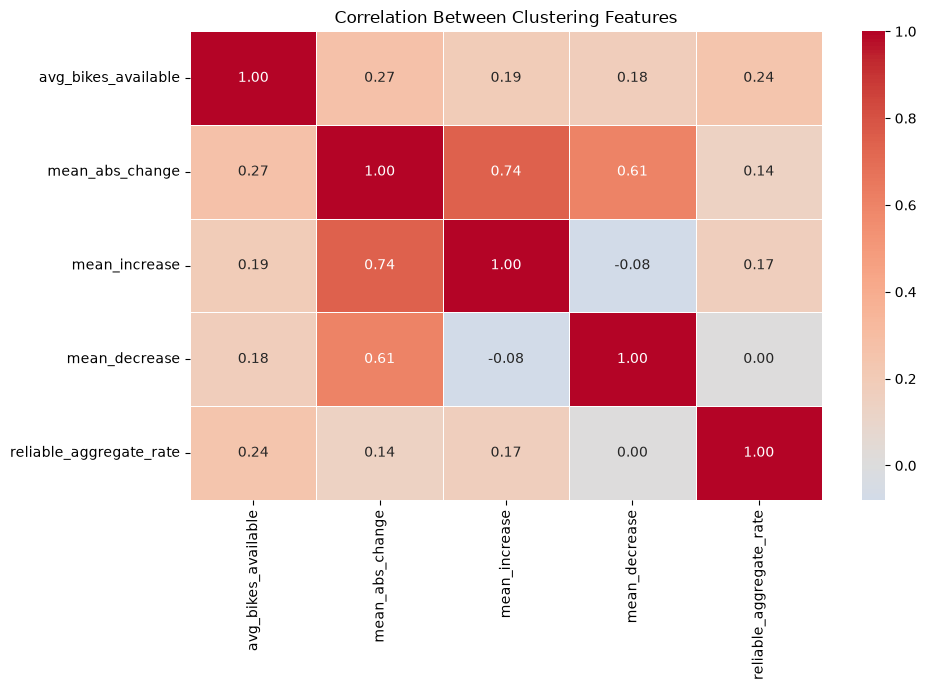

In [104]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlation matrix
correlation_matrix = X.corr()

# Display correlation values
display(correlation_matrix.round(3))

# Visualize correlations
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Between Clustering Features")
plt.tight_layout()
plt.show()

In [105]:
from sklearn.preprocessing import StandardScaler

# Initialize StandardScaler
scaler = StandardScaler()

# Standardize clustering features
X_scaled = scaler.fit_transform(X)

# Convert back to DataFrame
X_scaled = pd.DataFrame(
    X_scaled,
    columns=clustering_features,
    index=X.index
)

print("Scaled dataset shape:", X_scaled.shape)

print("\nScaled feature statistics:")
display(X_scaled.describe().round(3))

Scaled dataset shape: (2714, 5)

Scaled feature statistics:


,avg_bikes_available,mean_abs_change,mean_increase,mean_decrease,reliable_aggregate_rate
count,2714.000,2714.000,2714.000,2714.000,2714.000
mean,-0.000,0.000,-0.000,0.000,0.000
std,1.000,1.000,1.000,1.000,1.000
min,-1.044,-3.829,-3.038,-3.725,-0.881
25%,-0.504,-0.543,-0.584,-0.602,-0.470
50%,-0.188,-0.043,-0.097,0.040,-0.261
75%,0.323,0.472,0.414,0.577,0.137
max,23.614,8.911,8.901,9.181,17.684


In [106]:
# Investigate extreme standardized values

print("Extreme values (Z-score > 3):")

for column in X_scaled.columns:

    count = (X_scaled[column].abs() > 3).sum()

    percentage = count / len(X_scaled) * 100

    print(
        f"{column}: {count} ({percentage:.2f}%)"
    )

Extreme values (Z-score > 3):
avg_bikes_available: 19 (0.70%)
mean_abs_change: 42 (1.55%)
mean_increase: 44 (1.62%)
mean_decrease: 26 (0.96%)
reliable_aggregate_rate: 32 (1.18%)


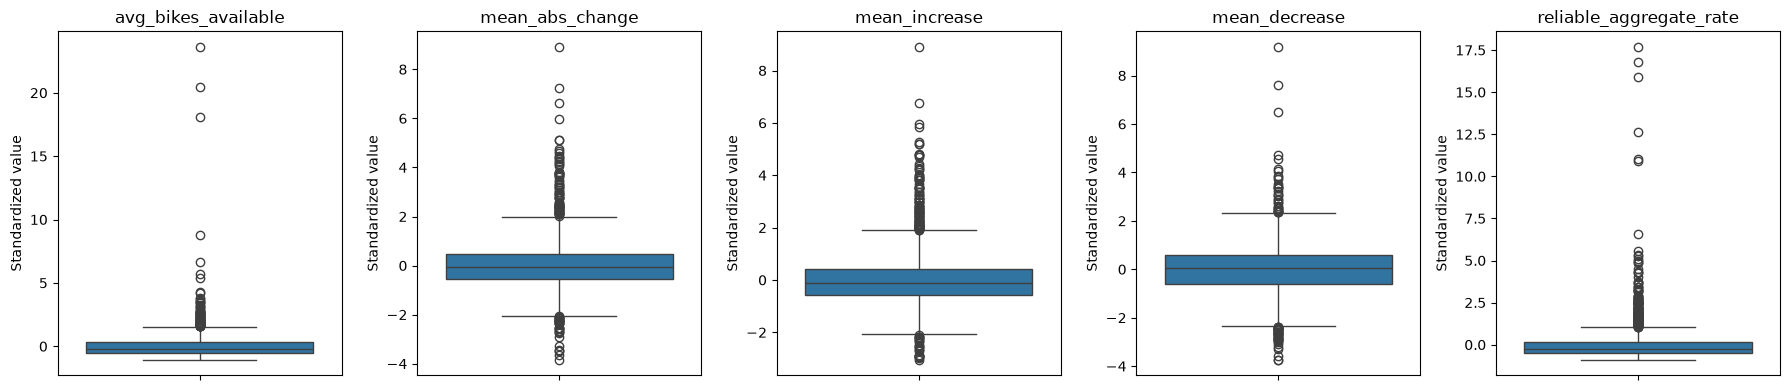

In [107]:


fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for i, column in enumerate(X_scaled.columns):

    sns.boxplot(
        y=X_scaled[column],
        ax=axes[i]
    )

    axes[i].set_title(column)
    axes[i].set_ylabel("Standardized value")

plt.tight_layout()
plt.show()

In [108]:
from sklearn.preprocessing import StandardScaler, RobustScaler

# Standard scaling
standard_scaler = StandardScaler()
X_standard = pd.DataFrame(
    standard_scaler.fit_transform(X),
    columns=X.columns,
    index=X.index
)

# Robust scaling
robust_scaler = RobustScaler()
X_robust = pd.DataFrame(
    robust_scaler.fit_transform(X),
    columns=X.columns,
    index=X.index
)

# Compare distributions
comparison = pd.DataFrame({
    "Standard Mean": X_standard.mean(),
    "Standard Std": X_standard.std(),
    "Robust Median": X_robust.median(),
    "Robust IQR": (
        X_robust.quantile(0.75) -
        X_robust.quantile(0.25)
    )
})

display(comparison.round(3))

,Standard Mean,Standard Std,Robust Median,Robust IQR
avg_bikes_available,-0.0,1.0,-0.0,1.0
mean_abs_change,0.0,1.0,0.0,1.0
mean_increase,-0.0,1.0,-0.0,1.0
mean_decrease,0.0,1.0,0.0,1.0
reliable_aggregate_rate,0.0,1.0,0.0,1.0


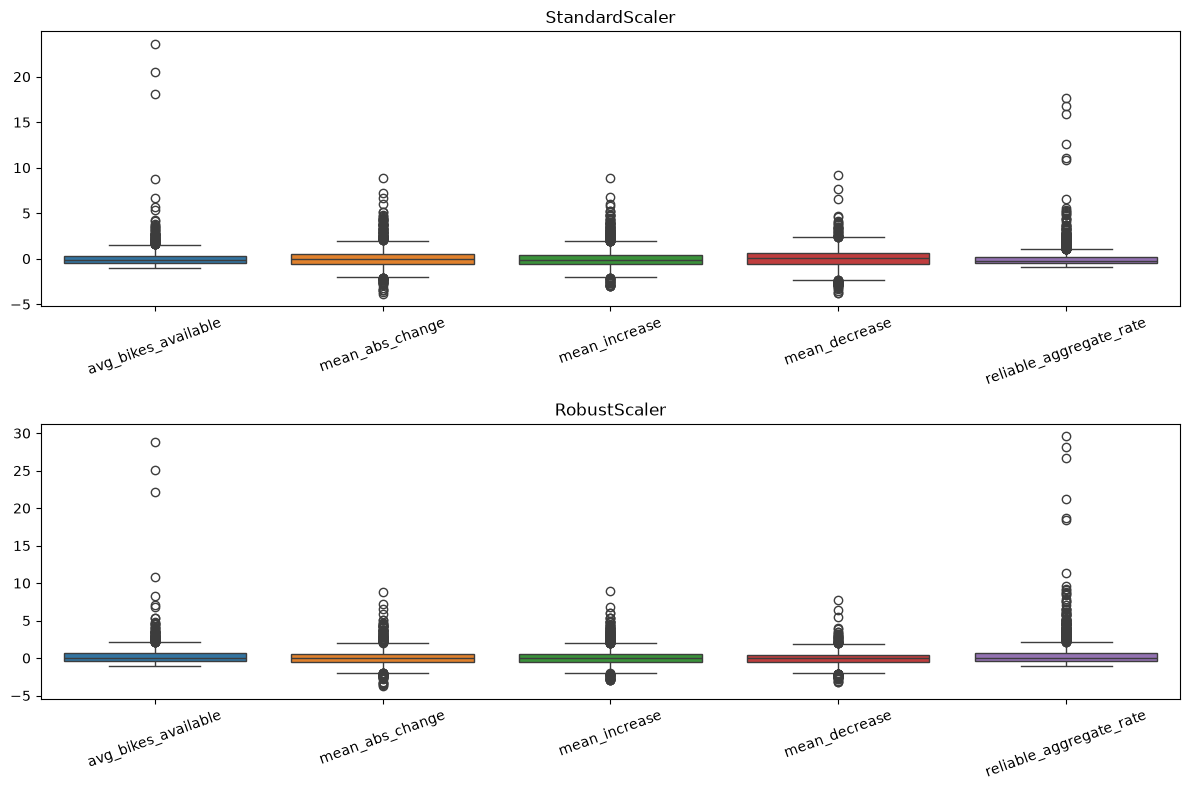

In [109]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))

sns.boxplot(data=X_standard, ax=axes[0])
axes[0].set_title("StandardScaler")
axes[0].tick_params(axis="x", rotation=20)

sns.boxplot(data=X_robust, ax=axes[1])
axes[1].set_title("RobustScaler")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

In [110]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

results = []

for scaler_name, scaled_data in [
    ("StandardScaler", X_standard),
    ("RobustScaler", X_robust)
]:

    for k in range(2, 11):

        kmeans = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=10
        )

        labels = kmeans.fit_predict(scaled_data)

        score = silhouette_score(
            scaled_data,
            labels
        )

        results.append({
            "Scaler": scaler_name,
            "K": k,
            "Silhouette Score": score,
            "Inertia": kmeans.inertia_
        })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Scaler,K,Silhouette Score,Inertia
0,StandardScaler,2,0.3161,10751.2823
1,StandardScaler,3,0.2585,9187.1513
2,StandardScaler,4,0.2617,7975.7931
3,StandardScaler,5,0.2648,6948.3162
4,StandardScaler,6,0.2860,5965.4068
5,StandardScaler,7,0.2639,5174.9680
6,StandardScaler,8,0.2770,4613.3256
7,StandardScaler,9,0.2333,4239.8965
8,StandardScaler,10,0.2361,3957.0431
9,RobustScaler,2,0.5453,14766.2955


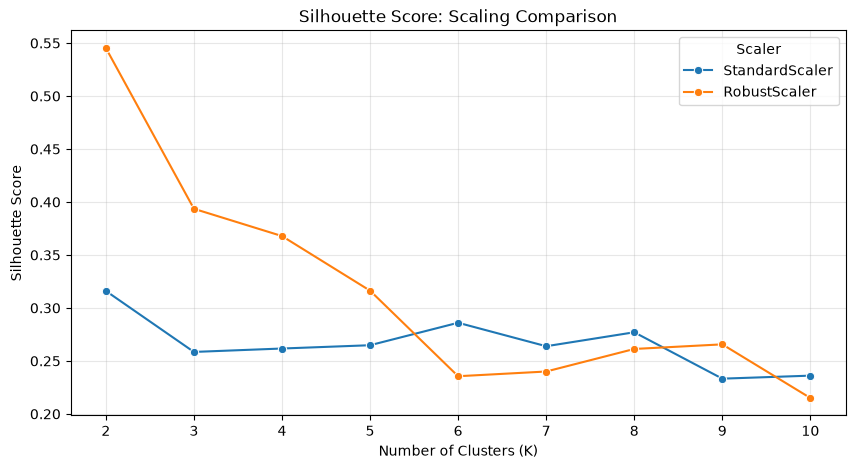

In [111]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=results_df,
    x="K",
    y="Silhouette Score",
    hue="Scaler",
    marker="o"
)

plt.title("Silhouette Score: Scaling Comparison")
plt.ylabel("Silhouette Score")
plt.xlabel("Number of Clusters (K)")
plt.xticks(range(2, 11))
plt.grid(alpha=0.3)
plt.show()

In [112]:
from sklearn.cluster import KMeans

cluster_results = []

for k in [2, 3, 4, 5]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_robust)

    # Cluster sizes
    sizes = pd.Series(labels).value_counts().sort_index()

    # Cluster characteristics
    profile = X.copy()
    profile["cluster"] = labels

    print(f"\n{'='*40}")
    print(f"K = {k}")
    print(f"{'='*40}")

    print("\nCluster sizes:")
    print(sizes)

    print("\nCluster profiles:")
    display(
        profile.groupby("cluster")[X.columns]
        .mean()
        .round(3)
    )


K = 2

Cluster sizes:
0     261
1    2453
Name: count, dtype: int64

Cluster profiles:


,avg_bikes_available,mean_abs_change,mean_increase,mean_decrease,reliable_aggregate_rate
cluster,,,,,
0,8.997,1.322,0.750,0.572,2.654
1,4.335,1.079,0.563,0.516,0.948



K = 3

Cluster sizes:
0    2161
1     547
2       6
Name: count, dtype: int64

Cluster profiles:


,avg_bikes_available,mean_abs_change,mean_increase,mean_decrease,reliable_aggregate_rate
cluster,,,,,
0,4.039,1.057,0.548,0.509,0.890
1,7.552,1.281,0.710,0.571,1.854
2,20.137,1.111,0.611,0.500,13.219



K = 4

Cluster sizes:
0    2088
1     618
2       5
3       3
Name: count, dtype: int64

Cluster profiles:


,avg_bikes_available,mean_abs_change,mean_increase,mean_decrease,reliable_aggregate_rate
cluster,,,,,
0,3.990,1.052,0.544,0.508,0.879
1,7.015,1.271,0.704,0.567,1.781
2,8.187,0.987,0.558,0.429,13.751
3,90.853,1.531,0.762,0.769,4.569



K = 5

Cluster sizes:
0     629
1    1879
2       5
3     198
4       3
Name: count, dtype: int64

Cluster profiles:


,avg_bikes_available,mean_abs_change,mean_increase,mean_decrease,reliable_aggregate_rate
cluster,,,,,
0,6.677,1.307,0.715,0.592,1.268
1,3.825,1.039,0.538,0.501,0.856
2,8.187,0.987,0.558,0.429,13.751
3,6.464,1.048,0.564,0.484,2.676
4,90.853,1.531,0.762,0.769,4.569


In [113]:
for k in [2, 3]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_robust)

    profile = X.copy()
    profile["cluster"] = labels

    print(f"\nK = {k}")

    print("\nCluster sizes:")
    print(profile["cluster"].value_counts().sort_index())

    print("\nCluster profiles (mean):")
    display(
        profile.groupby("cluster")[X.columns]
        .mean()
        .round(3)
    )

    print("\nCluster profiles (median):")
    display(
        profile.groupby("cluster")[X.columns]
        .median()
        .round(3)
    )


K = 2

Cluster sizes:
cluster
0     261
1    2453
Name: count, dtype: int64

Cluster profiles (mean):


,avg_bikes_available,mean_abs_change,mean_increase,mean_decrease,reliable_aggregate_rate
cluster,,,,,
0,8.997,1.322,0.750,0.572,2.654
1,4.335,1.079,0.563,0.516,0.948



Cluster profiles (median):


,avg_bikes_available,mean_abs_change,mean_increase,mean_decrease,reliable_aggregate_rate
cluster,,,,,
0,6.989,1.287,0.700,0.552,2.238
1,3.785,1.088,0.561,0.524,0.851



K = 3

Cluster sizes:
cluster
0    2161
1     547
2       6
Name: count, dtype: int64

Cluster profiles (mean):


,avg_bikes_available,mean_abs_change,mean_increase,mean_decrease,reliable_aggregate_rate
cluster,,,,,
0,4.039,1.057,0.548,0.509,0.890
1,7.552,1.281,0.710,0.571,1.854
2,20.137,1.111,0.611,0.500,13.219



Cluster profiles (median):


,avg_bikes_available,mean_abs_change,mean_increase,mean_decrease,reliable_aggregate_rate
cluster,,,,,
0,3.558,1.075,0.548,0.516,0.812
1,6.807,1.263,0.679,0.571,1.564
2,8.086,1.001,0.504,0.500,13.319


In [114]:


# Scale the cleaned dataset
scaler = RobustScaler()

X_robust = pd.DataFrame(
    scaler.fit_transform(X),
    columns=X.columns,
    index=X.index
)

# Compare K = 2 and K = 3
for k in [2, 3]:

    print("\n" + "=" * 50)
    print(f"K = {k}")
    print("=" * 50)

    # Train KMeans
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_robust)

    # Calculate silhouette score
    score = silhouette_score(X_robust, labels)

    print(f"\nSilhouette Score: {score:.4f}")

    # Use original values for interpretation
    profile = X.copy()
    profile["cluster"] = labels

    # Cluster sizes
    print("\nCluster Sizes:")
    print(profile["cluster"].value_counts().sort_index())

    # Mean profiles
    print("\nCluster Mean Profiles:")
    display(
        profile.groupby("cluster")[X.columns]
        .mean()
        .round(3)
    )

    # Median profiles
    print("\nCluster Median Profiles:")
    display(
        profile.groupby("cluster")[X.columns]
        .median()
        .round(3)
    )


K = 2

Silhouette Score: 0.5453

Cluster Sizes:
cluster
0     261
1    2453
Name: count, dtype: int64

Cluster Mean Profiles:


,avg_bikes_available,mean_abs_change,mean_increase,mean_decrease,reliable_aggregate_rate
cluster,,,,,
0,8.997,1.322,0.750,0.572,2.654
1,4.335,1.079,0.563,0.516,0.948



Cluster Median Profiles:


,avg_bikes_available,mean_abs_change,mean_increase,mean_decrease,reliable_aggregate_rate
cluster,,,,,
0,6.989,1.287,0.700,0.552,2.238
1,3.785,1.088,0.561,0.524,0.851



K = 3

Silhouette Score: 0.3936

Cluster Sizes:
cluster
0    2161
1     547
2       6
Name: count, dtype: int64

Cluster Mean Profiles:


,avg_bikes_available,mean_abs_change,mean_increase,mean_decrease,reliable_aggregate_rate
cluster,,,,,
0,4.039,1.057,0.548,0.509,0.890
1,7.552,1.281,0.710,0.571,1.854
2,20.137,1.111,0.611,0.500,13.219



Cluster Median Profiles:


,avg_bikes_available,mean_abs_change,mean_increase,mean_decrease,reliable_aggregate_rate
cluster,,,,,
0,3.558,1.075,0.548,0.516,0.812
1,6.807,1.263,0.679,0.571,1.564
2,8.086,1.001,0.504,0.500,13.319


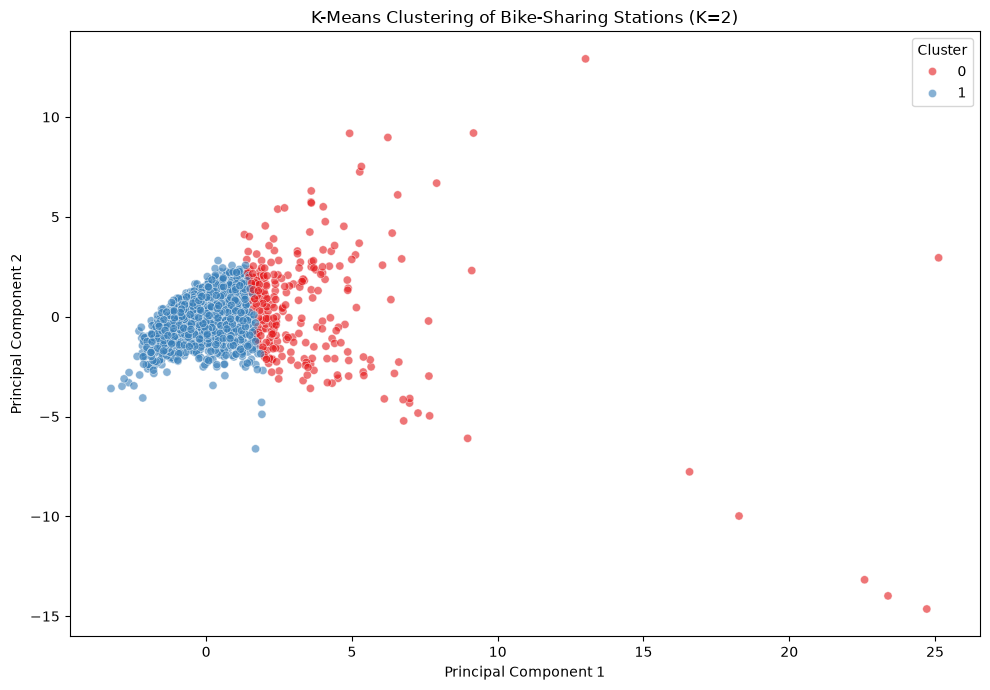

Explained variance ratio: [0.44545987 0.26345647]
Total variance explained: 70.89 %


In [115]:

final_model = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

final_labels = final_model.fit_predict(X_robust)

# Apply PCA
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_robust)

# Create dataframe for visualisation
pca_df = pd.DataFrame({
    "PCA1": X_pca[:, 0],
    "PCA2": X_pca[:, 1],
    "Cluster": final_labels
})

# Visualise clusters
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PCA1",
    y="PCA2",
    hue="Cluster",
    palette="Set1",
    alpha=0.6,
    s=35
)

plt.title("K-Means Clustering of Bike-Sharing Stations (K=2)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")

plt.tight_layout()
plt.show()

# Explained variance
print("Explained variance ratio:", pca.explained_variance_ratio_)
print(
    "Total variance explained:",
    round(sum(pca.explained_variance_ratio_) * 100, 2),
    "%"
)

In [116]:

cluster_results = station_features.loc[
    X_robust.index
].copy()

cluster_results["cluster"] = final_labels

# Examine stations in Cluster 0
high_activity_stations = (
    cluster_results[
        cluster_results["cluster"] == 0
    ]
    .sort_values(
        by="avg_bikes_available",
        ascending=False
    )
)

display(
    high_activity_stations[
        [
            "station_id",
            "name",
            "city_name",
            "country",
            "avg_bikes_available",
            "mean_abs_change",
            "reliable_aggregate_rate"
        ]
    ].head(20)
)

,station_id,name,city_name,country,avg_bikes_available,mean_abs_change,reliable_aggregate_rate
206,66397,Zweirad - Awe Strandpromenade Ückeritz 5516,Usedom,DE,102.818898,1.682709,1.938729
207,66400,Usedom Rad GmbH Zentrale 5555,Usedom,DE,89.853147,1.176211,1.208327
2682,132562406,"Taller - Bicicletas Cargando ""CHARGING BIKES""",Barcelona,ES,79.887399,1.734545,10.558488
578,746642,Central Milton Keynes - Train Station,Milton Keynes,GB,41.211755,0.972143,1.600478
248,82170,Bike Hotel Vaske Karlshagen 5553,Usedom,DE,32.430939,2.153226,1.455700
2320,76245743,DJH - Jugendherberge Prora 01,MV-Rad,DE,28.391304,1.937500,1.365644
200,66388,Naturcamping Lütow 5508,Usedom,DE,27.180328,2.000000,1.554989
325,153213,Kurverwaltung Seebad Lubmin 57139,MV-Rad,DE,22.550562,1.680851,1.059691
2818,159893772,virtuell - S-Bahnhof Erkner,Grünheide (Mark),DE,22.180652,1.154788,1.200717
205,66395,Strandhotel Seerose Kölpinsee 5515,Usedom,DE,20.573034,1.831579,1.035100


In [117]:
# capacity of high-activity stations

capacity_check = high_activity_stations[
    [
        "station_id",
        "name",
        "city_name",
        "total_capacity",
        "avg_bikes_available",
        "bike_racks",
        "special_racks"
    ]
].copy()


capacity_check["exceeds_capacity"] = (
    capacity_check["avg_bikes_available"]
    > capacity_check["total_capacity"]
)

display(capacity_check.head(20))

print("\nCapacity consistency:")
print(
    "Stations exceeding recorded capacity:",
    capacity_check["exceeds_capacity"].sum()
)

,station_id,name,city_name,total_capacity,avg_bikes_available,bike_racks,special_racks,exceeds_capacity
206,66397,Zweirad - Awe Strandpromenade Ückeritz 5516,Usedom,18,102.818898,18,0,True
207,66400,Usedom Rad GmbH Zentrale 5555,Usedom,0,89.853147,0,0,True
2682,132562406,"Taller - Bicicletas Cargando ""CHARGING BIKES""",Barcelona,0,79.887399,0,0,True
578,746642,Central Milton Keynes - Train Station,Milton Keynes,56,41.211755,56,0,False
248,82170,Bike Hotel Vaske Karlshagen 5553,Usedom,5,32.430939,5,0,True
2320,76245743,DJH - Jugendherberge Prora 01,MV-Rad,70,28.391304,70,0,False
200,66388,Naturcamping Lütow 5508,Usedom,20,27.180328,20,0,True
325,153213,Kurverwaltung Seebad Lubmin 57139,MV-Rad,20,22.550562,20,0,True
2818,159893772,virtuell - S-Bahnhof Erkner,Grünheide (Mark),10,22.180652,10,0,True
205,66395,Strandhotel Seerose Kölpinsee 5515,Usedom,5,20.573034,5,0,True



Capacity consistency:
Stations exceeding recorded capacity: 78


In [118]:


capacity_check = cluster_results.copy()

# Separate zero-capacity stations
zero_capacity = capacity_check[
    capacity_check["total_capacity"] == 0
]

# Positive-capacity stations
positive_capacity = capacity_check[
    capacity_check["total_capacity"] > 0
]

# Stations exceeding their recorded capacity
exceeding_capacity = positive_capacity[
    positive_capacity["avg_bikes_available"] >
    positive_capacity["total_capacity"]
]

print("CAPACITY CONSISTENCY REPORT")
print("=" * 45)

print("Total stations:", len(capacity_check))
print("Zero-capacity stations:", len(zero_capacity))
print("Positive-capacity stations:", len(positive_capacity))

print("Stations exceeding positive capacity:",
      len(exceeding_capacity))

print("Percentage exceeding positive capacity:",
      round(len(exceeding_capacity) /
            len(positive_capacity) * 100, 2), "%")

print("\nDistribution across clusters:")
print(exceeding_capacity["cluster"].value_counts())

print("\nTop 10 capacity inconsistencies:")
display(
    exceeding_capacity[
        ["station_id", "name", "city_name",
         "total_capacity", "avg_bikes_available", "cluster"]
    ].sort_values(
        "avg_bikes_available", ascending=False
    ).head(10)
)

CAPACITY CONSISTENCY REPORT
Total stations: 2714
Zero-capacity stations: 1117
Positive-capacity stations: 1597
Stations exceeding positive capacity: 104
Percentage exceeding positive capacity: 6.51 %

Distribution across clusters:
cluster
1    79
0    25
Name: count, dtype: int64

Top 10 capacity inconsistencies:


,station_id,name,city_name,total_capacity,avg_bikes_available,cluster
206,66397,Zweirad - Awe Strandpromenade Ückeritz 5516,Usedom,18,102.818898,0
248,82170,Bike Hotel Vaske Karlshagen 5553,Usedom,5,32.430939,0
200,66388,Naturcamping Lütow 5508,Usedom,20,27.180328,0
325,153213,Kurverwaltung Seebad Lubmin 57139,MV-Rad,20,22.550562,0
2818,159893772,virtuell - S-Bahnhof Erkner,Grünheide (Mark),10,22.180652,0
205,66395,Strandhotel Seerose Kölpinsee 5515,Usedom,5,20.573034,0
191,65937,Ferienwohnanlage `Alte Molkerei` Liepe 5533,Usedom,15,20.155556,0
369,205344,Trg kralja Tomislava,Zagreb,14,18.346494,0
2322,76246101,DJH - Jugendherberge Sellin 57105 01,MV-Rad,15,16.214286,1
2321,76245875,DJH - Jugendherberge Binz 57103,MV-Rad,15,15.875000,0


In [119]:
# Calculate capacity excess

capacity_issues = exceeding_capacity.copy()

capacity_issues["excess_bikes"] = (
    capacity_issues["avg_bikes_available"]
    - capacity_issues["total_capacity"]
)

capacity_issues["capacity_ratio"] = (
    capacity_issues["avg_bikes_available"]
    / capacity_issues["total_capacity"]
)

print("Capacity excess statistics:")
display(
    capacity_issues[
        ["excess_bikes", "capacity_ratio"]
    ].describe().round(2)
)

# Severity distribution
capacity_issues["severity"] = pd.cut(
    capacity_issues["capacity_ratio"],
    bins=[1, 1.5, 2, 5, float("inf")],
    labels=["Low", "Moderate", "High", "Extreme"]
)

print("\nSeverity distribution:")
display(capacity_issues["severity"].value_counts())

print("\nCapacity issues by cluster:")
display(
    capacity_issues.groupby("cluster")
    .agg(
        stations=("station_id", "count"),
        avg_excess=("excess_bikes", "mean"),
        avg_ratio=("capacity_ratio", "mean")
    ).round(2)
)

Capacity excess statistics:


,excess_bikes,capacity_ratio
count,104.00,104.00
mean,2.92,1.46
std,8.81,0.82
min,0.03,1.00
25%,0.60,1.11
50%,1.19,1.21
75%,2.22,1.45
max,84.82,6.49



Severity distribution:


severity
Low         81
Moderate    14
High         7
Extreme      2
Name: count, dtype: int64


Capacity issues by cluster:


,stations,avg_excess,avg_ratio
cluster,,,
0,25,8.03,1.97
1,79,1.30,1.30


In [120]:
# Top 15 stations with highest capacity ratios

top_capacity_issues = capacity_issues.sort_values(
    "capacity_ratio",
    ascending=False
)

display(
    top_capacity_issues[
        [
            "station_id",
            "name",
            "city_name",
            "total_capacity",
            "avg_bikes_available",
            "excess_bikes",
            "capacity_ratio",
            "cluster",
            "severity"
        ]
    ].head(15).round(2)
)

,station_id,name,city_name,total_capacity,avg_bikes_available,excess_bikes,capacity_ratio,cluster,severity
248,82170,Bike Hotel Vaske Karlshagen 5553,Usedom,5,32.43,27.43,6.49,0,Extreme
206,66397,Zweirad - Awe Strandpromenade Ückeritz 5516,Usedom,18,102.82,84.82,5.71,0,Extreme
205,66395,Strandhotel Seerose Kölpinsee 5515,Usedom,5,20.57,15.57,4.11,0,High
517,469547,Bazeni,Slavonski Brod,3,10.85,7.85,3.62,0,High
740,4775117,Kurt-Schumacher-Ring (Campus Mitte),Wiesbaden,4,12.26,8.26,3.07,0,High
1339,16852569,Kolovare,Zadar,1,2.66,1.66,2.66,1,High
2818,159893772,virtuell - S-Bahnhof Erkner,Grünheide (Mark),10,22.18,12.18,2.22,0,High
706,3562085,Špadići,Poreč,5,10.07,5.07,2.01,1,High
1065,10062397,Bahnhofsplatz,Dossenheim,6,12.02,6.02,2.00,1,High
2391,86927088,Verudela,Pula,2,3.74,1.74,1.87,1,Moderate


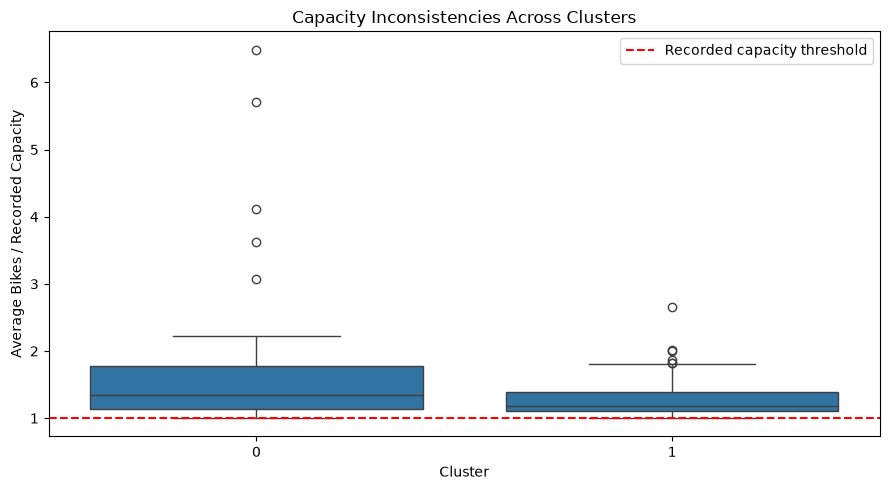

In [121]:


plt.figure(figsize=(9, 5))

sns.boxplot(
    data=capacity_issues,
    x="cluster",
    y="capacity_ratio"
)

plt.axhline(
    1,
    color="red",
    linestyle="--",
    label="Recorded capacity threshold"
)

plt.title("Capacity Inconsistencies Across Clusters")
plt.xlabel("Cluster")
plt.ylabel("Average Bikes / Recorded Capacity")
plt.legend()
plt.tight_layout()
plt.show()

In [122]:
# Final cluster characterization

final_cluster_summary = (
    cluster_results
    .groupby("cluster")
    .agg(
        station_count=("station_id", "count"),
        avg_bikes=("avg_bikes_available", "mean"),
        median_bikes=("avg_bikes_available", "median"),
        avg_activity=("reliable_aggregate_rate", "mean"),
        median_activity=("reliable_aggregate_rate", "median"),
        avg_abs_change=("mean_abs_change", "mean"),
        avg_increase=("mean_increase", "mean"),
        avg_decrease=("mean_decrease", "mean")
    )
)

final_cluster_summary["percentage"] = (
    final_cluster_summary["station_count"]
    / len(cluster_results) * 100
)

display(final_cluster_summary.round(3))

,station_count,avg_bikes,median_bikes,avg_activity,median_activity,avg_abs_change,avg_increase,avg_decrease,percentage
cluster,,,,,,,,,
0,261,8.997,6.989,2.654,2.238,1.322,0.750,0.572,9.617
1,2453,4.335,3.785,0.948,0.851,1.079,0.563,0.516,90.383


In [123]:

final_results = X.copy()

final_results["cluster"] = cluster_results["cluster"]


final_results["cluster_name"] = final_results["cluster"].map({
    0: "High Activity",
    1: "Lower Activity"
})

# Save results
final_results.to_csv(
    "../data/final_kmeans_clustering_results.csv",
    index=False
)

print("Final clustering results saved successfully!")

display(final_results.head())

Final clustering results saved successfully!


,avg_bikes_available,mean_abs_change,mean_increase,mean_decrease,reliable_aggregate_rate,cluster,cluster_name
0,3.707865,1.196429,0.678571,0.517857,1.895332,1,Lower Activity
1,3.246269,1.193939,0.642424,0.551515,1.208091,1,Lower Activity
2,4.016502,1.150943,0.580189,0.570755,1.339557,1,Lower Activity
3,2.863636,1.074074,0.654321,0.419753,2.287501,0,High Activity
4,3.950820,1.184211,0.605263,0.578947,1.632406,1,Lower Activity


In [124]:
# Preserve station metadata and clustering features

final_results = station_features.copy()

final_results["cluster"] = cluster_results["cluster"]

final_results["cluster_name"] = final_results["cluster"].map({
    0: "High Activity",
    1: "Lower Activity"
})

final_results.to_csv(
    "../reports/final_kmeans_clustering_results.csv",
    index=False
)

print("Final results with metadata saved!")
display(final_results.head())

Final results with metadata saved!


,station_id,avg_bikes_available,std_bikes_available,min_bikes_available,max_bikes_available,avg_bikes,avg_booked_bikes,avg_free_racks,avg_free_special_racks,maintenance_ratio,...,median_change_per_hour,activity_std,activity_observations,median_change_log,aggregate_change_per_hour,aggregate_change_log,reliable_aggregate_rate,has_reliable_activity,cluster,cluster_name
0,94,3.707865,1.582592,0,7,3.887640,0.179775,0.0,0.0,0.0,...,30.000000,1.290198,56.0,3.433987,1.895332,1.063100,1.895332,1,1.0,Lower Activity
1,522,3.246269,1.657743,0,9,3.369403,0.123134,0.0,0.0,0.0,...,7.058824,1.296422,165.0,2.086768,1.208091,0.792128,1.208091,1,1.0,Lower Activity
2,556,4.016502,1.738651,0,10,4.033003,0.016502,0.0,0.0,0.0,...,20.000000,1.215970,212.0,3.044522,1.339557,0.849962,1.339557,1,1.0,Lower Activity
3,568,2.863636,1.595666,0,7,2.969697,0.106061,0.0,0.0,0.0,...,20.000000,1.164813,81.0,3.044522,2.287501,1.190128,2.287501,1,0.0,High Activity
4,572,3.950820,2.028351,0,9,3.950820,0.000000,0.0,0.0,0.0,...,15.000000,1.262491,38.0,2.772589,1.632406,0.967898,1.632406,1,1.0,Lower Activity


In [125]:

final_results = station_features.copy()


final_results["cluster"] = cluster_results["cluster"].reindex(
    final_results.index
)


final_results["cluster_name"] = final_results["cluster"].map({
    0: "High Activity",
    1: "Lower Activity"
})


final_results["clustering_status"] = final_results["cluster"].apply(
    lambda x: "Clustered" if pd.notna(x) else "Not clustered"
)

display(final_results.head())

,station_id,avg_bikes_available,std_bikes_available,min_bikes_available,max_bikes_available,avg_bikes,avg_booked_bikes,avg_free_racks,avg_free_special_racks,maintenance_ratio,...,activity_std,activity_observations,median_change_log,aggregate_change_per_hour,aggregate_change_log,reliable_aggregate_rate,has_reliable_activity,cluster,cluster_name,clustering_status
0,94,3.707865,1.582592,0,7,3.887640,0.179775,0.0,0.0,0.0,...,1.290198,56.0,3.433987,1.895332,1.063100,1.895332,1,1.0,Lower Activity,Clustered
1,522,3.246269,1.657743,0,9,3.369403,0.123134,0.0,0.0,0.0,...,1.296422,165.0,2.086768,1.208091,0.792128,1.208091,1,1.0,Lower Activity,Clustered
2,556,4.016502,1.738651,0,10,4.033003,0.016502,0.0,0.0,0.0,...,1.215970,212.0,3.044522,1.339557,0.849962,1.339557,1,1.0,Lower Activity,Clustered
3,568,2.863636,1.595666,0,7,2.969697,0.106061,0.0,0.0,0.0,...,1.164813,81.0,3.044522,2.287501,1.190128,2.287501,1,0.0,High Activity,Clustered
4,572,3.950820,2.028351,0,9,3.950820,0.000000,0.0,0.0,0.0,...,1.262491,38.0,2.772589,1.632406,0.967898,1.632406,1,1.0,Lower Activity,Clustered


In [126]:
# Final quality checks

print("Total records:", len(final_results))
print("Unique station IDs:", final_results["station_id"].nunique())
print("Duplicate station IDs:",
      final_results["station_id"].duplicated().sum())

print("\nClustering coverage:")
print(
    round(
        final_results["cluster"].notna().mean() * 100, 2
    ), "%"
)

print("\nMissing values in clustering features:")
display(final_results[
    ["avg_bikes_available",
     "mean_abs_change",
     "mean_increase",
     "mean_decrease",
     "reliable_aggregate_rate"]
].isnull().sum())

print("\nCluster names:")
print(final_results["cluster_name"].value_counts(dropna=False))

Total records: 2899
Unique station IDs: 2899
Duplicate station IDs: 0

Clustering coverage:
93.62 %

Missing values in clustering features:


avg_bikes_available         0
mean_abs_change            23
mean_increase              23
mean_decrease              23
reliable_aggregate_rate     0
dtype: int64


Cluster names:
cluster_name
Lower Activity    2453
High Activity      261
NaN                185
Name: count, dtype: int64


In [127]:
# Check whether missing values occur in the same rows

activity_columns = [
    "mean_abs_change",
    "mean_increase",
    "mean_decrease"
]

missing_activity = final_results[
    activity_columns
].isnull().any(axis=1)

print("Stations with missing activity metrics:",
      missing_activity.sum())

print("\nMissing values by column:")
print(final_results[activity_columns].isnull().sum())

print("\nClustering status of these stations:")
print(
    final_results.loc[
        missing_activity, "clustering_status"
    ].value_counts()
)

print("\nSample missing records:")
display(
    final_results.loc[
        missing_activity,
        ["station_id"] + activity_columns + ["cluster_name"]
    ].head(10)
)

Stations with missing activity metrics: 23

Missing values by column:
mean_abs_change    23
mean_increase      23
mean_decrease      23
dtype: int64

Clustering status of these stations:
clustering_status
Not clustered    23
Name: count, dtype: int64

Sample missing records:


,station_id,mean_abs_change,mean_increase,mean_decrease,cluster_name
216,66417,NaN,NaN,NaN,NaN
228,68582,NaN,NaN,NaN,NaN
245,75016,NaN,NaN,NaN,NaN
334,187131,NaN,NaN,NaN,NaN
359,199130,NaN,NaN,NaN,NaN
362,200678,NaN,NaN,NaN,NaN
365,201001,NaN,NaN,NaN,NaN
367,202968,NaN,NaN,NaN,NaN
457,352855,NaN,NaN,NaN,NaN
490,405845,NaN,NaN,NaN,NaN


### Conclusion



We applied K-Means clustering to identify activity patterns among bike-sharing stations using bike availability, activity changes, and reliability metrics. After comparing different scaling approaches and cluster configurations, the RobustScaler-based K-Means model with K=2 achieved the highest silhouette score of 0.5453 among the evaluated configurations.


The resulting clusters identified two distinct station profiles: High Activity stations (261 stations, 9.62%) and Lower Activity stations (2,453 stations, 90.38%). The High Activity group demonstrated higher average bike availability and activity levels, while the Lower Activity group represented the majority of the stations.

Out of the 2,899 stations in the dataset, 2,714 stations were included in the clustering, while 185 were not clustered because they did not meet the data requirements for reliable activity-based analysis. This included 23 stations with missing activity metrics and stations with fewer than 10 activity observations

A separate capacity consistency analysis identified 104 stations exceeding their recorded positive capacity, representing 6.51% of stations with positive recorded capacity. Although most inconsistencies were classified as low severity, two stations exhibited extreme inconsistencies, highlighting the need for improved capacity monitoring and data validation.

Overall, the analysis demonstrates how unsupervised learning can help identify different operational patterns and potential data-quality issues in bike-sharing systems. The resulting clusters can support station monitoring, capacity planning, and resource redistribution decisions. However, the findings should be interpreted considering the exclusion of 185 stations from clustering, missing feature values, and the limitations of using aggregated activity metrics.

Future work could incorporate temporal demand patterns, geographical information, additional clustering algorithms, and real-time station availability to develop more comprehensive operational recommendations.